In [185]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import Levenshtein as lev
from scipy.stats import ttest_ind
import unicodedata
from scipy.stats import mannwhitneyu
from pca import pca
import networkx as nx

# Coleta e Organização dos Dados

## Dados de Volumetria do Almoço

In [4]:
df_volumetria_almoco = pd.read_csv('data/volumetria_almoco.csv')
df_volumetria_almoco.head()

,Data,RU,RA,RS,Total
0,2024-01-01,NaN,NaN,NaN,0
1,2024-01-02,870.0,142.0,0.0,1012
2,2024-01-03,1069.0,207.0,0.0,1276
3,2024-01-04,1177.0,208.0,0.0,1385
4,2024-01-05,1154.0,261.0,0.0,1415


In [5]:
def try_parsing_datetime(x):
    fmt = '%Y-%m-%d'
    try:
        return pd.to_datetime(x, format=fmt)
    except (ValueError, TypeError):
      return pd.NaT
df_volumetria_almoco['Data'] = df_volumetria_almoco['Data'].apply(try_parsing_datetime)

In [6]:
df_volumetria_almoco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 578 entries, 0 to 577
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Data    578 non-null    datetime64[ns]
 1   RU      378 non-null    float64       
 2   RA      363 non-null    float64       
 3   RS      525 non-null    float64       
 4   Total   578 non-null    int64         
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 22.7 KB


In [7]:
df_volumetria_almoco.head(20)

,Data,RU,RA,RS,Total
0,2024-01-01,NaN,NaN,NaN,0
1,2024-01-02,870.0,142.0,0.0,1012
2,2024-01-03,1069.0,207.0,0.0,1276
3,2024-01-04,1177.0,208.0,0.0,1385
4,2024-01-05,1154.0,261.0,0.0,1415
5,2024-01-06,NaN,NaN,NaN,0
6,2024-01-07,NaN,NaN,NaN,0
7,2024-01-08,1503.0,356.0,0.0,1859
8,2024-01-09,1638.0,416.0,0.0,2054
9,2024-01-10,1557.0,399.0,0.0,1956


## Dados de Volumetria da Janta

In [9]:
df_volumetria_janta = pd.read_csv('data/volumetria_janta.csv')

In [10]:
df_volumetria_janta['Data'] = df_volumetria_janta['Data'].apply(try_parsing_datetime)

In [11]:
df_volumetria_janta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 578 entries, 0 to 577
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Data    578 non-null    datetime64[ns]
 1   RU      379 non-null    float64       
 2   RA      363 non-null    float64       
 3   RS      459 non-null    float64       
 4   Total   578 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 22.7 KB


## Dados do Cardápio

In [12]:
df_cardapio = pd.read_csv('data/cardapio.csv')

In [13]:
df_cardapio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3963 entries, 0 to 3962
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   date            3963 non-null   object
 1   refeicao        3963 non-null   object
 2   acompanhamento  3963 non-null   object
 3   prato           3963 non-null   object
 4   guarnicao       3864 non-null   object
 5   opcao_vegetal   661 non-null    object
 6   salada          3963 non-null   object
 7   sobremesa       3963 non-null   object
 8   suco            3963 non-null   object
dtypes: object(9)
memory usage: 278.8+ KB


In [14]:
df_cardapio['date'] = df_cardapio['date'].apply(try_parsing_datetime)

In [15]:
df_cardapio_almoco_padrao = df_cardapio[df_cardapio['refeicao'] == "Almoço - Cardápio Padrão"]

In [16]:
df_cardapio_janta_padrao = df_cardapio[df_cardapio['refeicao'] == "Jantar - Cardápio Padrão"]

In [63]:
df_cardapio_almoco_padrao.head(10)

,refeicao,acompanhamento,prato,guarnicao,opcao_vegetal,salada,sobremesa,suco
date,,,,,,,,
2025-08-15,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,"PUCHERO (CUBOS SUÍNO, LINGUIÇA CALABRESA, CENO...",VIRADO DE COUVE,NaN,SALADA DE REPOLHO VERDE E ROXO,LARANJA,REFRESCO SABOR GOIABA
2025-08-14,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,FRICASSÊ DE FRANGO,"ARROZ COLORIDO (ERVILHA, MILHO, CENOURA E SALSA)",NaN,SALADA DE BETERRABA RALADA (RS /HC / CAISM) SA...,SAGU DE UVA,REFRESCO DE LARANJA
2025-08-13,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,PESCADA AO MOLHO DE AZEITONAS,CENOURA NA SALSA,NaN,SALADA DE ALFACE,BANANA,REFRESCO DE ACEROLA
2025-08-12,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,SOBRECOXA DE PANELA NA SALSA,BERINJELA AO SUGO,NaN,SALADA DE ESCAROLA COM NABO RALADO,MAÇÃ,REFRESCO DE MORANGO
2025-08-11,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,CARNE MOÍDA A PRIMAVERA (MILHO E ERVILHA),ANGÚ DE MILHO,NaN,SALADA DE ALFACE,BARRA DE CEREAL,REFRESCO DE MANGA
2025-08-10,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,BIFE AO MOLHO ESCURO,ABOBRINHA REFOGADA,NaN,SALADA DE COUVE,MAÇÃ,REFRESCO DE UVA
2025-08-09,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,ISCAS DE FRANGO AO MOLHO FERRUGEM,CENOURA SAUTÉ,NaN,SALADA DE ALFACE,BARRA DE CEREAL,REFRESCO DE ABACAXI
2025-08-08,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,CUBOS SUÍNOS AO MOLHO BARBECUE,VIRADO DE ESCAROLA,NaN,SALADA DE BETERRABA RALADA,TANGERINA,REFRESCO DE LIMÃO
2025-08-07,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,ISCAS DE CARNE AO MOLHO ESCURO (RU),REFOGADO DE LEGUMES (RA/HC) | PURÊ DE BATATA ...,NaN,SALADA MIX DE ALFACE,MAÇÃ,REFRESCO DE PÊSSEGO


## Dados de Precipitação

In [19]:
df_precipitacao_2024 = pd.read_csv('data/precip_horarios_2024_Cepagri.csv')

In [25]:
df_precipitacao_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Data          8763 non-null   int64
 1   Hora          8763 non-null   int64
 2   Precipitação  8763 non-null   int64
dtypes: int64(3)
memory usage: 205.5 KB


In [21]:
df_precipitacao_2024.head(10)

,Data,Hora,Precipitação
0,1,1210,0
1,1,1220,0
2,1,1230,0
3,1,1240,0
4,1,1250,0
5,1,1300,0
6,1,1310,0
7,1,1320,0
8,1,1330,0
9,1,1340,0


In [28]:
prec_por_refeicao_2024 = df_precipitacao_2024["Precipitação"].groupby(df_precipitacao_2024.index // 12).sum()

In [29]:
df_prec_por_refeicao_2024 = prec_por_refeicao_2024.to_frame()

In [30]:
df_prec_por_refeicao_2024

,Precipitação
0,0
1,0
2,0
3,0
4,0
...,...
726,3302
727,0
728,0
729,0


In [31]:
df_prec_por_refeicao_2024["Refeição"] = df_prec_por_refeicao_2024.index.map(lambda x: "Almoço" if x % 2 == 0 else "Jantar")

In [32]:
df_prec_por_refeicao_2024

,Precipitação,Refeição
0,0,Almoço
1,0,Jantar
2,0,Almoço
3,0,Jantar
4,0,Almoço
...,...,...
726,3302,Almoço
727,0,Jantar
728,0,Almoço
729,0,Jantar


In [33]:
df_prec_almoco_2024 = df_prec_por_refeicao_2024[df_prec_por_refeicao_2024['Refeição'] == "Almoço"]

In [34]:
df_prec_almoco_2024

,Precipitação,Refeição
0,0,Almoço
2,0,Almoço
4,0,Almoço
6,0,Almoço
8,0,Almoço
...,...,...
722,0,Almoço
724,0,Almoço
726,3302,Almoço
728,0,Almoço


In [35]:
df_prec_janta_2024 = df_prec_por_refeicao_2024[df_prec_por_refeicao_2024['Refeição'] == "Jantar"]

In [36]:
df_prec_janta_2024

,Precipitação,Refeição
1,0,Jantar
3,0,Jantar
5,8636,Jantar
7,0,Jantar
9,0,Jantar
...,...,...
721,0,Jantar
723,0,Jantar
725,2667,Jantar
727,0,Jantar


In [37]:
df_precipitacao_2025 = pd.read_csv('data/precip_horarios_2025parcial_Cepagri.csv')

In [38]:
df_precipitacao_2025

,Data,Hora,Precipitação
0,1,1210,0
1,1,1220,0
2,1,1230,0
3,1,1240,0
4,1,1250,0
...,...,...,...
5659,236,1920,0
5660,236,1930,0
5661,236,1940,0
5662,236,1950,0


In [39]:
prec_por_refeicao_2025 = df_precipitacao_2025["Precipitação"].groupby(df_precipitacao_2025.index // 12).sum()

In [40]:
df_prec_por_refeicao_2025 = prec_por_refeicao_2025.to_frame()

In [41]:
df_prec_por_refeicao_2025

,Precipitação
0,0
1,0
2,0
3,0
4,0
...,...
467,0
468,0
469,0
470,0


In [42]:
df_prec_por_refeicao_2025["Refeição"] = df_prec_por_refeicao_2025.index.map(lambda x: "Almoço" if x % 2 == 0 else "Jantar")

In [43]:
df_prec_por_refeicao_2025

,Precipitação,Refeição
0,0,Almoço
1,0,Jantar
2,0,Almoço
3,0,Jantar
4,0,Almoço
...,...,...
467,0,Jantar
468,0,Almoço
469,0,Jantar
470,0,Almoço


In [44]:
df_prec_almoco_2025 = df_prec_por_refeicao_2025[df_prec_por_refeicao_2025['Refeição'] == "Almoço"]

In [45]:
df_prec_janta_2025 = df_prec_por_refeicao_2025[df_prec_por_refeicao_2025['Refeição'] == "Jantar"]

In [46]:
df_prec_janta_2025

,Precipitação,Refeição
1,0,Jantar
3,0,Jantar
5,0,Jantar
7,0,Jantar
9,0,Jantar
...,...,...
463,0,Jantar
465,0,Jantar
467,0,Jantar
469,0,Jantar


In [47]:
df_prec_almoco_2024_2025 = pd.concat([df_prec_almoco_2024, df_prec_almoco_2025])

In [48]:
df_prec_almoco_2024_2025

,Precipitação,Refeição
0,0,Almoço
2,0,Almoço
4,0,Almoço
6,0,Almoço
8,0,Almoço
...,...,...
462,0,Almoço
464,0,Almoço
466,0,Almoço
468,0,Almoço


In [49]:
df_prec_janta_2024_2025 = pd.concat([df_prec_janta_2024, df_prec_janta_2025])

In [50]:
df_prec_janta_2024_2025

,Precipitação,Refeição
1,0,Jantar
3,0,Jantar
5,8636,Jantar
7,0,Jantar
9,0,Jantar
...,...,...
463,0,Jantar
465,0,Jantar
467,0,Jantar
469,0,Jantar


In [ ]:
df_prec_janta_2024_2025 = df_prec_janta_2024_2025.reset_index(drop=True)

In [52]:
df_prec_almoco_2024_2025 = df_prec_almoco_2024_2025.reset_index(drop=True)

In [54]:
df_prec_janta_2024_2025

,Precipitação,Refeição
0,0,Jantar
1,0,Jantar
2,8636,Jantar
3,0,Jantar
4,0,Jantar
...,...,...
596,0,Jantar
597,0,Jantar
598,0,Jantar
599,0,Jantar


## Tabela Principal

Criando a main do almoço e da janta a partir da tabela da volumetria

In [55]:
main_almoco_raw = df_volumetria_almoco

In [56]:
main_janta_raw = df_volumetria_janta

In [57]:
main_almoco_raw["Precipitação"] = df_prec_almoco_2024_2025["Precipitação"].reindex(main_almoco_raw.index)

In [58]:
main_janta_raw["Precipitação"] = df_prec_janta_2024_2025["Precipitação"].reindex(main_janta_raw.index)

In [59]:
main_almoco_raw = main_almoco_raw.set_index("Data")

In [60]:
main_janta_raw = main_janta_raw.set_index("Data")

In [61]:
df_cardapio_almoco_padrao = df_cardapio_almoco_padrao.set_index("date")

In [62]:
df_cardapio_janta_padrao = df_cardapio_janta_padrao.set_index("date")

In [64]:
main_almoco_raw = main_almoco_raw.join(df_cardapio_almoco_padrao["prato"], how="left")

In [65]:
main_janta_raw = main_janta_raw.join(df_cardapio_janta_padrao["prato"], how="left")

In [66]:
main_janta_raw = main_janta_raw.rename(columns={"prato": "Prato Principal"})


In [67]:
main_almoco_raw = main_almoco_raw.rename(columns={"prato": "Prato Principal"})

In [68]:
main_almoco_raw

,RU,RA,RS,Total,Precipitação,Prato Principal
Data,,,,,,
2024-01-01,NaN,NaN,NaN,0,0,NaN
2024-01-02,870.0,142.0,0.0,1012,0,STROGONOFF DE FRANGO
2024-01-03,1069.0,207.0,0.0,1276,0,PERNIL ASSADO AO MOLHO ESCURO (MOLHOS SHOYO E ...
2024-01-04,1177.0,208.0,0.0,1385,0,CARNE DE PANELA COM AZEITONA
2024-01-05,1154.0,261.0,0.0,1415,0,"CARNE ASSADA À ROMANESCA (PRESUNTO, ERVILHA E..."
...,...,...,...,...,...,...
2025-07-27,0.0,NaN,799.0,799,0,ISCA DE FRANGO GRATINADA
2025-07-28,1509.0,625.0,422.0,2556,0,CUBOS SUÍNOS COM ABACAXI (RS/RA) | CUBOS DE FR...
2025-07-29,1825.0,691.0,454.0,2970,0,ISCAS DE CARNE AO MOLHO RÚSTICO COM AZEITONAS


In [69]:
main_almoco_sem_nan = main_almoco_raw.dropna().copy()

In [70]:
main_janta_sem_nan = main_janta_raw.dropna().copy()

In [71]:
main_janta_sem_nan

,RU,RA,RS,Total,Precipitação,Prato Principal
Data,,,,,,
2024-01-02,400.0,50.0,0.0,450.0,0,"BIFE AO MOLHO ROTY (CALDO DE CARNE, MOLHO SHOY..."
2024-01-03,482.0,72.0,0.0,554.0,8636,ISCAS DE FRANGO ACEBOLADO
2024-01-04,608.0,83.0,0.0,691.0,0,PERNIL SUÍNO AO MOLHO DE ABACAXI
2024-01-05,478.0,71.0,0.0,549.0,0,CARNE EM CUBOS AO POMODORO
2024-01-08,749.0,114.0,0.0,863.0,0,SALSICHA AO SUGO
...,...,...,...,...,...,...
2025-07-25,862.0,194.0,90.0,1146.0,0,FEIJOADA
2025-07-28,598.0,178.0,101.0,877.0,0,PESCADA AO BRÁS
2025-07-29,1085.0,311.0,146.0,1542.0,0,"ISCAS DE FRANGO À CHINESA (BRÓCOLIS, CENOURA, ..."


In [72]:
categorias = {}

def tirar_acento(texto):
  texto_normalizado = unicodedata.normalize('NFKD', texto)
  texto_sem_acentos = ''.join(c for c in texto_normalizado if not unicodedata.combining(c))
  return texto_sem_acentos

def limpar(descricao):
  # tirar tudo depois de parenteses
  descricao = descricao.split('(')[0]
  descricao = descricao.lower()
  descricao = tirar_acento(descricao)
  descricao_palavras = descricao.split()
  palavras_reais = []
  for palavra in descricao_palavras:
    if len(palavras_reais) == 2:
      break
    if len(palavra) > 3:
      palavras_reais.append(palavra)
  descricao = ' '.join(palavras_reais)
  return descricao

def categorizar(descricao):
  threshold = 0.8
  descricao_limpa = limpar(descricao)
  for categoria in categorias.keys():
    if lev.ratio(descricao_limpa, categoria) > threshold:
      categorias[categoria].append(descricao)
      return categoria
  categorias[descricao_limpa] = [descricao]
  return descricao_limpa


main_almoco_sem_nan["Categoria do Prato"] = main_almoco_sem_nan["Prato Principal"].apply(categorizar)
main_janta_sem_nan["Categoria do Prato"] = main_janta_sem_nan["Prato Principal"].apply(categorizar)

In [73]:
categorias

{'strogonoff frango': ['STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO',
  'STROGONOFF DE FRANGO (RU, RA e HC) / NUGGETS (RS)',
  'STROGONOFF DE FRANGO'],
 'pernil assado': ['PERNIL ASSADO AO MOLHO ESCURO (MOLHOS SHOYO E INGLÊS)',
  'PERNIL ASSADO AO MOLHO DE LIMÃO',
  'PERNIL ASSADO AO MOLHO BARBECUE'],
 'carne panela': ['CARNE DE PANELA  COM AZEITONA',
  'CARNE DE PANELA AO MOLHO ESCURO COM LEGUMES (CENOURA E CHUCHU)',
  'CARNE DE PANELA ACEBOLADA',
  'CARNE DE PANELA COM BATATA',
  'CARNE DE PANELA AO MOLHO ROTY'],
 'carne assada': ['CARNE ASSADA À ROMANESCA  (PRESUNTO, ERVILHA E MOLHO BRANCO)',
  'CARNE ASSADA AO MOLHO ROTY (MOLHO INGLÊS E SHOYO)',
  'CARNE ASSADA AO MOLHO MOSTARDA',
  'CARNE ASSADA AO VINAGRETE QUENTE (RS, RA e HC), CARNE EM CUBOS AO VINAGRETE (RU)',
  'CARNE ASSADA AO MOLHO ESCURO',
 

In [74]:
def juntar_categorias(categoria):
  if 'bife' in categoria:
    return 'bife'
  if 'sobrecoxa' in categoria:
    return 'sobrecoxa'
  if 'bisteca' in categoria:
    return 'bisteca'
  if 'guizado' in categoria:
    return 'guizado'
  if 'salsicha' in categoria:
    return 'salsicha'
  if 'linguica' in categoria:
    return 'linguica'
  if 'lagarto' in categoria:
    return 'lagarto'
  if 'quibe' in categoria:
    return 'quibe'
  if 'almondega' in categoria:
    return 'almondega'
  if 'pernil' in categoria:
    return 'pernil'
  peixes_keywords = ['tilapia', 'peixe', 'pescada']
  for keyword in peixes_keywords:
    if keyword in categoria:
      return 'peixe'
  strogonoff_keywords = ['strogonoff', 'strognoff']
  for keyword in strogonoff_keywords:
    if keyword in categoria:
      return 'strogonoff'
  filedefrango_keywords = ['filezinho frango', 'sassami']
  for keyword in filedefrango_keywords:
    if keyword in categoria:
      return 'file de frango'
  carne_cubos_categorias = ['carne cubos', 'cubos carne', 'cubos bovinos', 'patinho cubos']
  for carne_cubos_categoria in carne_cubos_categorias:
    if carne_cubos_categoria == categoria:
      return 'carne cubos'
  picado_carne_categorias = ['picadinho carne', 'picado bovino']
  for picado_carne_categoria in picado_carne_categorias:
    if picado_carne_categoria == categoria:
      return 'picadinho carne'
  outros_cortes_de_porco = ['copa lombo', 'paleta suina', 'pernil assado']
  for corte_de_porco in outros_cortes_de_porco:
    if corte_de_porco == categoria:
      return 'outros cortes de porco'
  carne_de_penela_categorias = ['goulash carne', 'carne panela']
  for carne_de_penela_categoria in carne_de_penela_categorias:
    if carne_de_penela_categoria == categoria:
      return 'carne de panela'
  iscas_de_carne_categorias = ['iscas carne', 'isca bovina']
  for iscas_de_carne_categoria in iscas_de_carne_categorias:
    if iscas_de_carne_categoria == categoria:
      return 'iscas de carne'
  steak_keywords = ['steak', 'empanado frango']
  for keyword in steak_keywords:
    if keyword in categoria:
      return 'steak'
  return categoria


main_almoco_sem_nan["Categoria do Prato"] = main_almoco_sem_nan["Categoria do Prato"].apply(juntar_categorias)
main_janta_sem_nan["Categoria do Prato"] = main_janta_sem_nan["Categoria do Prato"].apply(juntar_categorias)

In [75]:
almoco_categorias = main_almoco_sem_nan.groupby("Categoria do Prato")["Total"].mean()
almoco_categorias

Categoria do Prato
almondega                 8168.000000
bife                      5685.744681
bisteca                   5041.200000
bobo frango               6273.000000
carne assada              6200.000000
carne cubos               5720.800000
carne de panela           5183.000000
carne louca               7199.000000
carne moida               5872.550000
cozido misto              6764.000000
cubos frango              6777.000000
cubos suinos              5274.545455
feijoada                  6542.111111
file de frango            5954.266667
frango assado             6520.000000
frango caipira            4299.000000
frango ensopado           6242.000000
frango xadrez             2976.000000
fricasse frango           7843.000000
fritada americana         6818.000000
isca frango               5480.466667
iscas de carne            4766.814815
lagarto                   6744.250000
linguica                  5826.727273
nuggets frango            7768.500000
outros cortes de porco    5745.

In [76]:
almoco_categorias_ordenadas = almoco_categorias.sort_values(ascending=False)

In [77]:
almoco_categorias_ordenadas

Categoria do Prato
almondega                 8168.000000
fricasse frango           7843.000000
nuggets frango            7768.500000
carne louca               7199.000000
fritada americana         6818.000000
cubos frango              6777.000000
cozido misto              6764.000000
lagarto                   6744.250000
feijoada                  6542.111111
frango assado             6520.000000
puchero                   6327.500000
sobrecoxa                 6285.583333
bobo frango               6273.000000
frango ensopado           6242.000000
carne assada              6200.000000
strogonoff                5997.454545
file de frango            5954.266667
carne moida               5872.550000
linguica                  5826.727273
outros cortes de porco    5745.714286
carne cubos               5720.800000
bife                      5685.744681
isca frango               5480.466667
cubos suinos              5274.545455
carne de panela           5183.000000
bisteca                   5041.

In [78]:
janta_categorias = main_janta_sem_nan.groupby("Categoria do Prato")["Total"].mean()
janta_categorias

Categoria do Prato
almondega                 4763.250000
bife                      3152.641026
bisteca                   3455.263158
carne assada              3653.888889
carne bovina              4414.000000
carne cubos               2745.882353
carne de panela           3641.000000
carne moida               3615.058824
carne picada              2554.000000
cozido misto              4029.000000
cubos suinos              3362.047619
feijoada                  2980.555556
file de frango            3712.148148
frango assado             4228.000000
frango desfiado           1553.000000
frango espanhola          2459.000000
frango molho              3902.500000
frango pizzaiolo          4882.000000
fricasse frango           2670.500000
guizado                   2974.750000
isca frango               3287.400000
iscas de carne            3311.535714
lagarto                   3107.750000
linguica                  3084.777778
nuggets frango            4522.500000
outros cortes de porco    3179.

In [79]:
janta_categorias_ordenadas = janta_categorias.sort_values(ascending=False)

In [80]:
janta_categorias_ordenadas

Categoria do Prato
yakissoba frango          4904.000000
frango pizzaiolo          4882.000000
almondega                 4763.250000
picadinho carne           4574.500000
nuggets frango            4522.500000
peito frango              4501.000000
carne bovina              4414.000000
frango assado             4228.000000
cozido misto              4029.000000
strogonoff                3910.785714
frango molho              3902.500000
file de frango            3712.148148
sobrecoxa                 3688.176214
carne assada              3653.888889
carne de panela           3641.000000
carne moida               3615.058824
bisteca                   3455.263158
quibe                     3392.333333
cubos suinos              3362.047619
iscas de carne            3311.535714
isca frango               3287.400000
salsicha                  3207.500000
outros cortes de porco    3179.400000
bife                      3152.641026
lagarto                   3107.750000
linguica                  3084.

In [83]:
main_almoco_sem_nan

,RU,RA,RS,Total,Precipitação,Prato Principal,Categoria do Prato
Data,,,,,,,
2024-01-02,870.0,142.0,0.0,1012,0,STROGONOFF DE FRANGO,strogonoff
2024-01-03,1069.0,207.0,0.0,1276,0,PERNIL ASSADO AO MOLHO ESCURO (MOLHOS SHOYO E ...,pernil
2024-01-04,1177.0,208.0,0.0,1385,0,CARNE DE PANELA COM AZEITONA,carne de panela
2024-01-05,1154.0,261.0,0.0,1415,0,"CARNE ASSADA À ROMANESCA (PRESUNTO, ERVILHA E...",carne assada
2024-01-08,1503.0,356.0,0.0,1859,0,BIFE AO MOLHO ROTY,bife
...,...,...,...,...,...,...,...
2025-07-25,1782.0,555.0,417.0,2754,1016,FEIJOADA,feijoada
2025-07-28,1509.0,625.0,422.0,2556,0,CUBOS SUÍNOS COM ABACAXI (RS/RA) | CUBOS DE FR...,cubos suinos
2025-07-29,1825.0,691.0,454.0,2970,0,ISCAS DE CARNE AO MOLHO RÚSTICO COM AZEITONAS,iscas de carne


In [ ]:
######################## TOTAL ####################################
nao_letivo = [
    ("2024-01-01", "2024-02-28"),
    ("2024-07-06", "2024-08-01"),
    ("2024-12-07", "2025-02-24")]

def filtrar_letivo(df):
    mask = pd.Series(True, index=df.index)
    for inicio, fim in nao_letivo:
        mask &= ~((df.index >= pd.to_datetime(inicio)) & (df.index <= pd.to_datetime(fim)))
    return df[mask]

def filtrar_nao_letivo(df):
    mask = pd.Series(False, index=df.index)
    for inicio, fim in nao_letivo:
        mask |= (df.index >= pd.to_datetime(inicio)) & (df.index <= pd.to_datetime(fim))
    return df[mask]

# Filtro de apenas valores positivos (ou seja, quando os restaurantes estão abertos)
main_almoco = main_almoco_sem_nan[main_almoco_sem_nan["Total"] > 0]
main_janta  = main_janta_sem_nan[main_janta_sem_nan["Total"] > 0]

# Só dias da semana
main_almoco_semana = main_almoco[main_almoco.index.weekday < 5]
main_janta_semana  = main_janta[main_janta.index.weekday < 5]

# Só finais de semana
main_almoco_fds = main_almoco[main_almoco.index.weekday >= 5]
main_janta_fds  = main_janta[main_janta.index.weekday >= 5]

# Só dias no período letivo
main_almoco_letivo = filtrar_letivo(main_almoco)
main_janta_letivo  = filtrar_letivo(main_janta)

# Só dias no período não letivo
main_almoco_nao_letivo = filtrar_nao_letivo(main_almoco)
main_janta_nao_letivo  = filtrar_nao_letivo(main_janta)

# Só finais de semana letivo
main_almoco_fds_letivo = filtrar_letivo(main_almoco_fds)
main_janta_fds_letivo  = filtrar_letivo(main_janta_fds)

# Só finais de semana no período não letivo
main_almoco_fds_nao_letivo = filtrar_nao_letivo(main_almoco_fds)
main_janta_fds_nao_letivo  = filtrar_nao_letivo(main_janta_fds)

# Só dias da semana em período letivo
main_almoco_semana_letivo = filtrar_letivo(main_almoco_semana)
main_janta_semana_letivo  = filtrar_letivo(main_janta_semana)

# Só dias da semana em período não letivo
main_almoco_semana_nao_letivo = filtrar_nao_letivo(main_almoco_semana)
main_janta_semana_nao_letivo  = filtrar_nao_letivo(main_janta_semana)


# Plotagem e Analíse Exploratória dos Dados

## Média (RU+RA+RS) com e sem chuva - Semana - Período letivo

C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\4196346452.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  main_almoco_semana_letivo["Chuva_simples"] = np.where(
C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\4196346452.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  main_janta_semana_letivo["Chuva_simples"] = np.where(
C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\4196346452.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
T

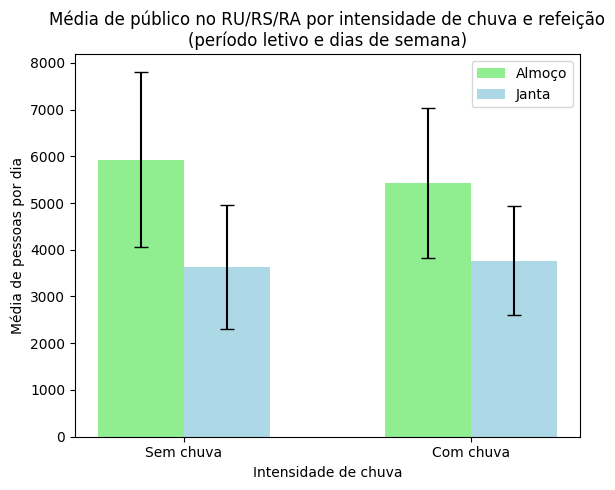

Mann-Whitney U test Almoço: U = 3178.00, p-value = 0.0472
Mann-Whitney U test Janta: U = 2946.00, p-value = 0.7921


In [116]:
# --- Rótulos para o gráfico ---
labels_simples = ["Sem chuva", "Com chuva"]

# --- Criar coluna Precipitação_mm ---
# main_almoco_semana_letivo["Precipitação_mm"] = main_almoco["Precipitação"] / (1000 * 2)
# main_janta_semana_letivo["Precipitação_mm"] = main_janta["Precipitação"] / (1000 * 2)

# --- Criar coluna de chuva simplificada ---
main_almoco_semana_letivo["Chuva_simples"] = np.where(
    main_almoco_semana_letivo["Precipitação"] == 0,
    "Sem chuva", "Com chuva"
)
main_janta_semana_letivo["Chuva_simples"] = np.where(
    main_janta_semana_letivo["Precipitação"] == 0,
    "Sem chuva", "Com chuva"
)

# --- Adicionar coluna "Refeição" (opcional, útil para rastrear origem) ---
main_almoco_semana_letivo["Refeição"] = "Almoço"
main_janta_semana_letivo["Refeição"] = "Janta"

# --- Juntar os dois DataFrames ---
main_total_semana_letivo = pd.concat(
    [main_almoco_semana_letivo, main_janta_semana_letivo],
    ignore_index=True
)

# --- Calcular médias e desvios padrão por grupo de chuva ---
"""
media_total = main_total_semana_letivo.groupby("Chuva_simples")["Total"].mean().reindex(labels_simples)
std_total   = main_total_semana_letivo.groupby("Chuva_simples")["Total"].std().reindex(labels_simples)
"""
media_almoco = main_almoco_semana_letivo.groupby("Chuva_simples")["Total"].mean().reindex(labels_simples)
std_almoco   = main_almoco_semana_letivo.groupby("Chuva_simples")["Total"].std().reindex(labels_simples)
media_janta  = main_janta_semana_letivo.groupby("Chuva_simples")["Total"].mean().reindex(labels_simples)
std_janta    = main_janta_semana_letivo.groupby("Chuva_simples")["Total"].std().reindex(labels_simples)

# --- Teste de Mann-Whitney U (dados não paramétricos, independentes) ---
sem_chuva_almoco = main_almoco_semana_letivo[main_almoco_semana_letivo["Chuva_simples"] == "Sem chuva"]["Total"]
com_chuva_almoco = main_almoco_semana_letivo[main_almoco_semana_letivo["Chuva_simples"] == "Com chuva"]["Total"]
sem_chuva_janta  = main_janta_semana_letivo[main_janta_semana_letivo["Chuva_simples"] == "Sem chuva"]["Total"]
com_chuva_janta  = main_janta_semana_letivo[main_janta_semana_letivo["Chuva_simples"] == "Com chuva"]["Total"]

stat_almoco, p_almoco = mannwhitneyu(sem_chuva_almoco, com_chuva_almoco, alternative='two-sided')
stat_janta, p_janta = mannwhitneyu(sem_chuva_janta, com_chuva_janta, alternative='two-sided')

# --- Plot do gráfico ---
x = np.arange(len(labels_simples))

plt.figure(figsize=(6, 5))
plt.bar([a - 0.15 for a in x], media_almoco, yerr=std_almoco, capsize=5, color='lightgreen', width=0.3, label='Almoço')
plt.bar([a + 0.15 for a in x], media_janta, yerr=std_janta, capsize=5, color='lightblue', width=0.3, label='Janta')

plt.xticks(x, labels_simples)
plt.xlabel("Intensidade de chuva")
plt.ylabel("Média de pessoas por dia")
plt.title("Média de público no RU/RS/RA por intensidade de chuva e refeição\n(período letivo e dias de semana)")
plt.legend()

plt.tight_layout()
plt.show()

# --- Imprimir resultado do teste no terminal ---
print(f"Mann-Whitney U test Almoço: U = {stat_almoco:.2f}, p-value = {p_almoco:.4f}\nMann-Whitney U test Janta: U = {stat_janta:.2f}, p-value = {p_janta:.4f}")



Shapiro-Wilk - Almoço Sem Chuva: ShapiroResult(statistic=np.float64(0.8902234267827648), pvalue=np.float64(3.0769025697246524e-13))
Shapiro-Wilk - Almoço Com Chuva: ShapiroResult(statistic=np.float64(0.8917160972680962), pvalue=np.float64(0.041301092444666135))
Shapiro-Wilk - Janta Sem Chuva: ShapiroResult(statistic=np.float64(0.9400937438948259), pvalue=np.float64(6.508911967364176e-09))
Shapiro-Wilk - Janta Com Chuva: ShapiroResult(statistic=np.float64(0.8704917040311845), pvalue=np.float64(0.006550710514765739))


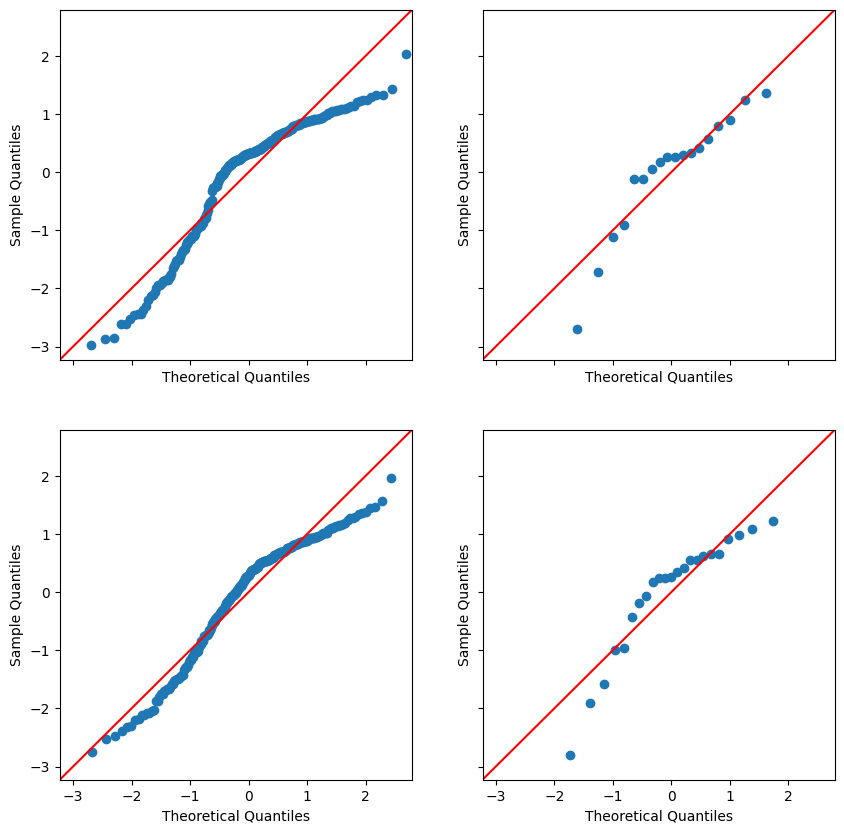

In [176]:
import scipy.stats as stats
import statsmodels.api as sm

# Almoço
shapiro_sem_chuva_almoco = stats.shapiro(sem_chuva_almoco)
shapiro_com_chuva_almoco = stats.shapiro(com_chuva_almoco)

# Janta
shapiro_sem_chuva_janta = stats.shapiro(sem_chuva_janta)
shapiro_com_chuva_janta = stats.shapiro(com_chuva_janta)

print("Shapiro-Wilk - Almoço Sem Chuva:", shapiro_sem_chuva_almoco)
print("Shapiro-Wilk - Almoço Com Chuva:", shapiro_com_chuva_almoco)
print("Shapiro-Wilk - Janta Sem Chuva:", shapiro_sem_chuva_janta)
print("Shapiro-Wilk - Janta Com Chuva:", shapiro_com_chuva_janta)

fig, axes = plt.subplots(2, 2, figsize=(10,10), sharex=True, sharey=True)
fig_com_almoco = sm.qqplot(sem_chuva_almoco, dist=stats.norm, fit=True, line='45', ax = axes[0,0])
sm.qqplot(com_chuva_almoco, dist=stats.norm, fit=True, line='45', ax = axes[0,1])
sm.qqplot(sem_chuva_janta, dist=stats.norm, fit=True, line='45', ax = axes[1,0])
sm.qqplot(com_chuva_janta, dist=stats.norm, fit=True, line='45', ax = axes[1,1])
plt.show()

In [120]:
from scipy.stats import kruskal
import scikit_posthocs as sp
import pandas as pd

# Juntar os dados em um único DataFrame
df_dunn = pd.concat([
    sem_chuva_almoco.to_frame(name='Total').assign(Grupo='Almoço Sem Chuva'),
    com_chuva_almoco.to_frame(name='Total').assign(Grupo='Almoço Com Chuva'),
    sem_chuva_janta.to_frame(name='Total').assign(Grupo='Janta Sem Chuva'),
    com_chuva_janta.to_frame(name='Total').assign(Grupo='Janta Com Chuva'),
])

# Kruskal-Wallis
kruskal_result = kruskal(
    df_dunn[df_dunn['Grupo'] == 'Almoço Sem Chuva']['Total'],
    df_dunn[df_dunn['Grupo'] == 'Almoço Com Chuva']['Total'],
    df_dunn[df_dunn['Grupo'] == 'Janta Sem Chuva']['Total'],
    df_dunn[df_dunn['Grupo'] == 'Janta Com Chuva']['Total']
)
print(f"Kruskal-Wallis: H = {kruskal_result.statistic:.2f}, p = {kruskal_result.pvalue:.4f}")

# Pós-hoc: Dunn com correção de Bonferroni
dunn_result = sp.posthoc_dunn(df_dunn, val_col='Total', group_col='Grupo', p_adjust='bonferroni')
print("\nTeste de Dunn (p-valores):")
print(dunn_result)


Kruskal-Wallis: H = 195.57, p = 0.0000

Teste de Dunn (p-valores):
                  Almoço Com Chuva  Almoço Sem Chuva  Janta Com Chuva  \
Almoço Com Chuva          1.000000      1.000000e+00         0.027124   
Almoço Sem Chuva          1.000000      1.000000e+00         0.000001   
Janta Com Chuva           0.027124      1.041611e-06         1.000000   
Janta Sem Chuva           0.000757      1.134139e-41         1.000000   

                  Janta Sem Chuva  
Almoço Com Chuva     7.573101e-04  
Almoço Sem Chuva     1.134139e-41  
Janta Com Chuva      1.000000e+00  
Janta Sem Chuva      1.000000e+00  


## Comparação média entre período letivo e não letivo

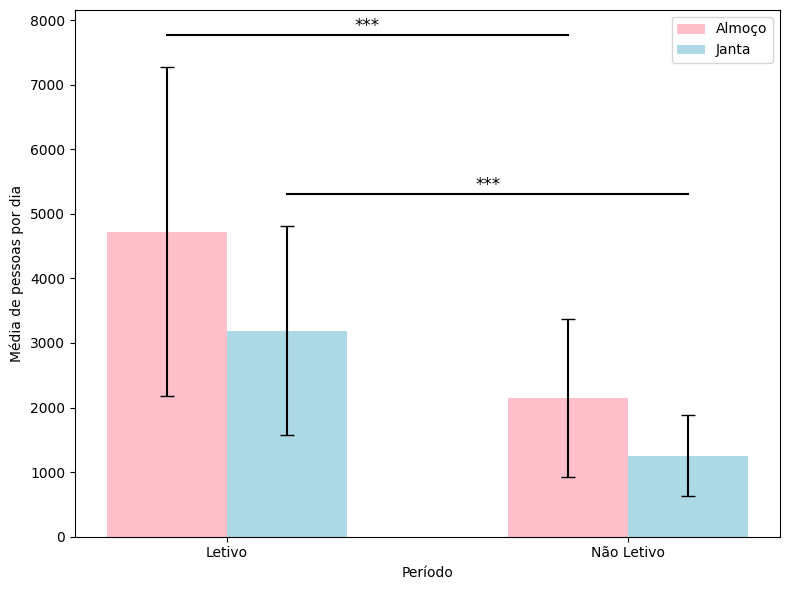

Almoço: U-stat = 44667.50, p-value = 0.00000
Janta:  U-stat = 32440.00, p-value = 0.00000


In [178]:
# Calcular médias e desvios padrão
media_almoco_letivo  = main_almoco_letivo["Total"].mean()
media_janta_letivo   = main_janta_letivo["Total"].mean()
media_almoco_nao_letivo = main_almoco_nao_letivo["Total"].mean()
media_janta_nao_letivo  = main_janta_nao_letivo["Total"].mean()

std_almoco_letivo  = main_almoco_letivo["Total"].std()
std_janta_letivo   = main_janta_letivo["Total"].std()
std_almoco_nao_letivo = main_almoco_nao_letivo["Total"].std()
std_janta_nao_letivo  = main_janta_nao_letivo["Total"].std()

# Criar listas organizadas para plotagem
media_almoco = [media_almoco_letivo, media_almoco_nao_letivo]
std_almoco   = [std_almoco_letivo, std_almoco_nao_letivo]

media_janta  = [media_janta_letivo, media_janta_nao_letivo]
std_janta    = [std_janta_letivo, std_janta_nao_letivo]

labels = ["Letivo", "Não Letivo"]

# --- Testes estatísticos ---
stat_almoco, p_almoco = mannwhitneyu(
    main_almoco_letivo["Total"],
    main_almoco_nao_letivo["Total"],
    alternative='two-sided'
)

stat_janta, p_janta = mannwhitneyu(
    main_janta_letivo["Total"],
    main_janta_nao_letivo["Total"],
    alternative='two-sided'
)

# --- Função para converter p-valor em asteriscos ---
def get_significance(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'  # Não significativo

# --- Plot ---
x = np.arange(len(labels))
bar_width = 0.3
fig, ax = plt.subplots(figsize=(8,6))

# Barras
bars_almoco = ax.bar(x - 0.15, media_almoco, yerr=std_almoco, capsize=5, width=bar_width, color='pink', label='Almoço')
bars_janta  = ax.bar(x + 0.15, media_janta, yerr=std_janta, capsize=5, width=bar_width, color='lightblue', label='Janta')

# Eixos e título
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Média de pessoas por dia")
ax.set_xlabel("Período")

ax.legend()

# --- Adicionando significância ---
def add_significance_bar(ax, x1, x2, y, h, p_value, text_offset=2):
    """Adiciona a linha de comparação e p-valor"""
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='black')
    significance = get_significance(p_value)
    ax.text((x1 + x2)/2, y + h + text_offset, significance, ha='center', va='bottom', fontsize=12)

# Posição vertical (y) baseada no valor máximo das barras + erro
y_max_almoco = max([bar.get_height() + err for bar, err in zip(bars_almoco, std_almoco)])
y_max_janta  = max([bar.get_height() + err for bar, err in zip(bars_janta, std_janta)])

# Ajuste vertical das barras de significância
add_significance_bar(ax, x[0]-0.15, x[1]-0.15, y_max_almoco + 500, h=1.5, p_value=p_almoco)  # Almoço
add_significance_bar(ax, x[0]+0.15, x[1]+0.15, y_max_janta + 500, h=1.5, p_value=p_janta)    # Janta

plt.tight_layout()
plt.show()

# Print dos valores exatos
print(f"Almoço: U-stat = {stat_almoco:.2f}, p-value = {p_almoco:.5f}")
print(f"Janta:  U-stat = {stat_janta:.2f}, p-value = {p_janta:.5f}")


## Comparação média entre período letivo e não letivo (Semana)

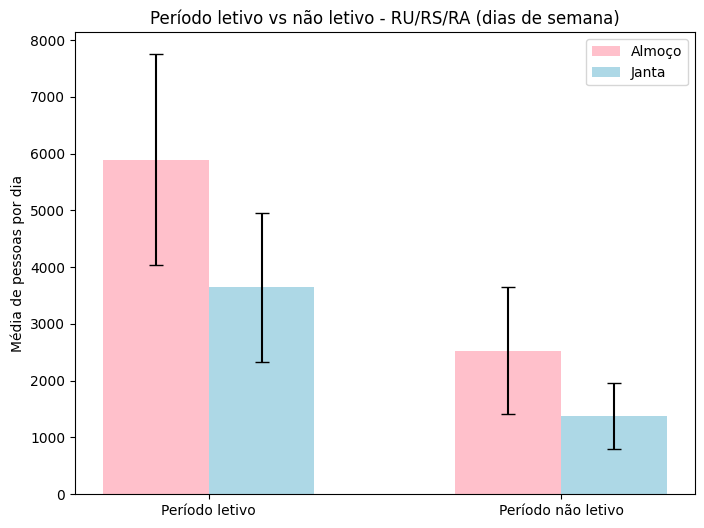

Almoço: U-stat = 30237.50, p-value = 0.0000
Janta:  U-stat = 27154.00, p-value = 0.0000


In [180]:
# Calcular médias e desvios padrão
media_almoco_semana_letivo  = main_almoco_semana_letivo["Total"].mean()
media_janta_semana_letivo   = main_janta_semana_letivo["Total"].mean()
media_almoco_semana_nao_letivo = main_almoco_semana_nao_letivo["Total"].mean()
media_janta_semana_nao_letivo  = main_janta_semana_nao_letivo["Total"].mean()

std_almoco_semana_letivo  = main_almoco_semana_letivo["Total"].std()
std_janta_semana_letivo   = main_janta_semana_letivo["Total"].std()
std_almoco_semana_nao_letivo = main_almoco_semana_nao_letivo["Total"].std()
std_janta_semana_nao_letivo  = main_janta_semana_nao_letivo["Total"].std()

# Criar listas organizadas para plotagem
media_almoco = [media_almoco_semana_letivo, media_almoco_semana_nao_letivo]
std_almoco   = [std_almoco_semana_letivo, std_almoco_semana_nao_letivo]

media_janta  = [media_janta_semana_letivo, media_janta_semana_nao_letivo]
std_janta    = [std_janta_semana_letivo, std_janta_semana_nao_letivo]

labels = ["Período letivo", "Período não letivo"]

# --- Plot ---
x = np.arange(len(labels))
plt.figure(figsize=(8,6))
plt.bar(x - 0.15, media_almoco, yerr=std_almoco, capsize=5, width=0.3, color='pink', label='Almoço')
plt.bar(x + 0.15, media_janta, yerr=std_janta, capsize=5, width=0.3, color='lightblue', label='Janta')
plt.xticks(x, labels)
plt.ylabel("Média de pessoas por dia")
plt.title("Período letivo vs não letivo - RU/RS/RA (dias de semana)")
plt.legend()
plt.show()


# Comparar Almoço - letivo vs não letivo
stat_almoco, p_almoco = mannwhitneyu(
    main_almoco_semana_letivo["Total"],
    main_almoco_semana_nao_letivo["Total"],
    alternative='two-sided'
)

# Comparar Janta - letivo vs não letivo
stat_janta, p_janta = mannwhitneyu(
    main_janta_semana_letivo["Total"],
    main_janta_semana_nao_letivo["Total"],
    alternative='two-sided'
)

print(f"Almoço: U-stat = {stat_almoco:.2f}, p-value = {p_almoco:.4f}")
print(f"Janta:  U-stat = {stat_janta:.2f}, p-value = {p_janta:.4f}")




## Comparação média entre período letivo e não letivo (Finais de Semana)

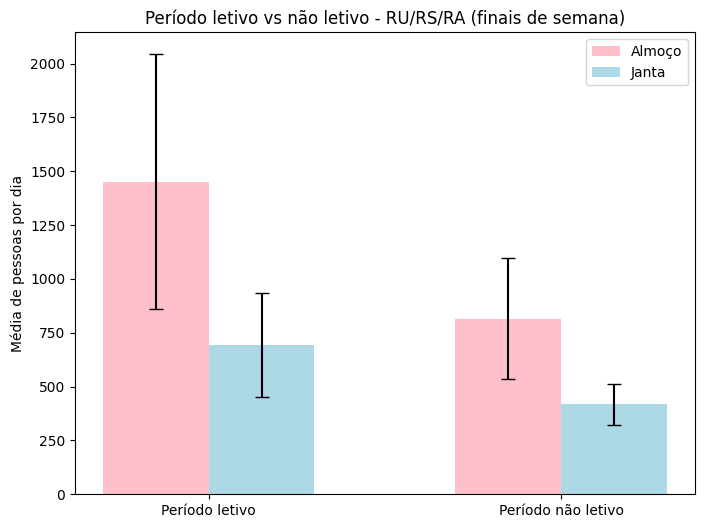

Almoço: U-stat = 2931.50, p-value = 0.0000
Janta:  U-stat = 632.50, p-value = 0.0000


In [182]:
# Calcular médias e desvios padrão
media_almoco_fds_letivo  = main_almoco_fds_letivo["Total"].mean()
media_janta_fds_letivo   = main_janta_fds_letivo["Total"].mean()
media_almoco_fds_nao_letivo = main_almoco_fds_nao_letivo["Total"].mean()
media_janta_fds_nao_letivo  = main_janta_fds_nao_letivo["Total"].mean()

std_almoco_fds_letivo  = main_almoco_fds_letivo["Total"].std()
std_janta_fds_letivo   = main_janta_fds_letivo["Total"].std()
std_almoco_fds_nao_letivo = main_almoco_fds_nao_letivo["Total"].std()
std_janta_fds_nao_letivo  = main_janta_fds_nao_letivo["Total"].std()

# Criar listas organizadas para plotagem
media_almoco = [media_almoco_fds_letivo, media_almoco_fds_nao_letivo]
std_almoco   = [std_almoco_fds_letivo, std_almoco_fds_nao_letivo]

media_janta  = [media_janta_fds_letivo, media_janta_fds_nao_letivo]
std_janta    = [std_janta_fds_letivo, std_janta_fds_nao_letivo]

labels = ["Período letivo", "Período não letivo"]

# --- Plot ---
x = np.arange(len(labels))
plt.figure(figsize=(8,6))
plt.bar(x - 0.15, media_almoco, yerr=std_almoco, capsize=5, width=0.3, color='pink', label='Almoço')
plt.bar(x + 0.15, media_janta, yerr=std_janta, capsize=5, width=0.3, color='lightblue', label='Janta')
plt.xticks(x, labels)
plt.ylabel("Média de pessoas por dia")
plt.title("Período letivo vs não letivo - RU/RS/RA (finais de semana)")
plt.legend()
plt.show()

# Comparar Almoço - letivo vs não letivo
stat_almoco, p_almoco = mannwhitneyu(
    main_almoco_fds_letivo["Total"],
    main_almoco_fds_nao_letivo["Total"],
    alternative='two-sided'
)

# Comparar Janta - letivo vs não letivo
stat_janta, p_janta = mannwhitneyu(
    main_janta_fds_letivo["Total"],
    main_janta_fds_nao_letivo["Total"],
    alternative='two-sided'
)

print(f"Almoço: U-stat = {stat_almoco:.2f}, p-value = {p_almoco:.4f}")
print(f"Janta:  U-stat = {stat_janta:.2f}, p-value = {p_janta:.4f}")


## Comparação entre dias da semana - Letivo

Kruskal–Wallis: H = 231.79, p = 0.0000


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\1135280979.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="DiaSemana", y="Total", data=main_total, order=dias_ordem, palette="pastel")


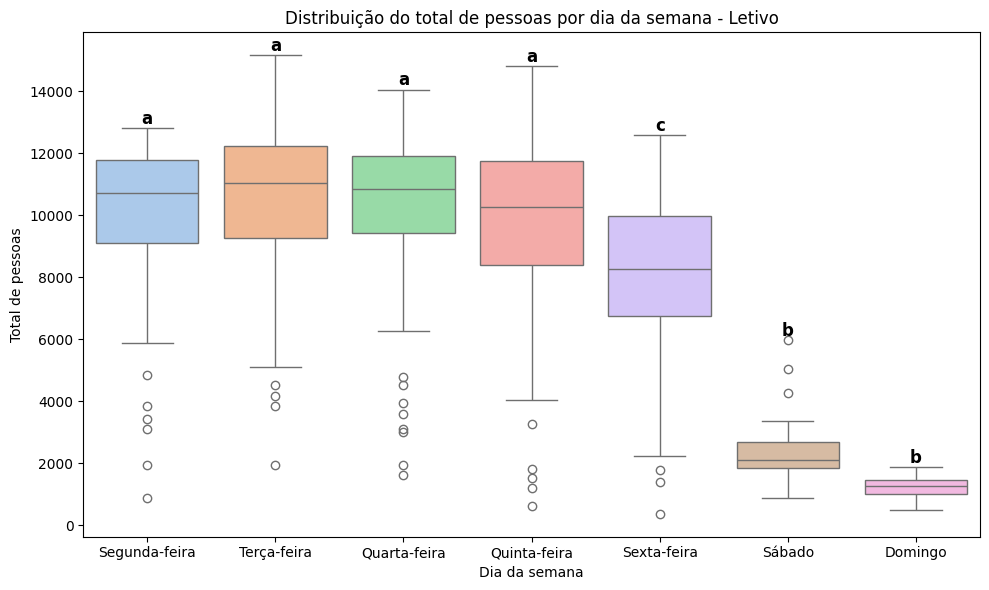

In [186]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# Combinar almoço e janta, mantendo todos os dias
dias_todos = main_almoco_letivo.index.union(main_janta_letivo.index)

main_total = pd.DataFrame({
    "Total": main_almoco_letivo.reindex(dias_todos)["Total"].fillna(0) +
             main_janta_letivo.reindex(dias_todos)["Total"].fillna(0)
})

# Adicionar coluna com o nome do dia da semana
# Mapeia os dias da semana (0 = segunda, 6 = domingo)
dias_dict = {
    0: "Segunda-feira",
    1: "Terça-feira",
    2: "Quarta-feira",
    3: "Quinta-feira",
    4: "Sexta-feira",
    5: "Sábado",
    6: "Domingo"
}

main_total["DiaSemana"] = main_total.index.weekday.map(dias_dict)

dias_ordem = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]

# Teste Kruskal–Wallis
grupos = [main_total.loc[main_total["DiaSemana"] == d, "Total"] for d in dias_ordem]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# Teste post hoc de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="DiaSemana", p_adjust="bonferroni")

# Função para gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    """
    Gera letras de significância para um DataFrame de p-valores de comparações múltiplas.

    Parâmetros:
    - df_p: DataFrame simétrico de p-valores (ex: saída de posthoc_dunn)
    - alpha: nível de significância (padrão = 0.05)

    Retorna:
    - dicionário {grupo: letras}
    """
    grupos = df_p.index.tolist()
    G = nx.Graph()

    # Adiciona nós
    G.add_nodes_from(grupos)

    # Adiciona arestas entre grupos que NÃO são significativamente diferentes
    for i, g1 in enumerate(grupos):
        for j, g2 in enumerate(grupos):
            if j <= i:
                continue
            p_val = df_p.loc[g1, g2]
            if p_val > alpha or np.isnan(p_val):  # Não significativamente diferentes
                G.add_edge(g1, g2)

    # Lista de letras
    letras_disponiveis = list("abcdefghijklmnopqrstuvwxyz")
    letras_grupos = {g: "" for g in grupos}
    letra_idx = 0

    # Enquanto ainda houver nós sem letras
    while G.number_of_nodes() > 0:
        # Encontrar um clique máximo (grupos que podem compartilhar uma letra)
        clique = nx.find_cliques(G)
        clique = sorted(clique, key=lambda x: -len(x))[0]  # maior clique
        letra = letras_disponiveis[letra_idx]
        for grupo in clique:
            letras_grupos[grupo] += letra
            G.remove_node(grupo)  # remover para que não receba mais letras
        letra_idx += 1

    return letras_grupos

letras = gerar_letras(dunn)

#  Plot com seaborn
plt.figure(figsize=(10,6))
sns.boxplot(x="DiaSemana", y="Total", data=main_total, order=dias_ordem, palette="pastel")
plt.title("Distribuição do total de pessoas por dia da semana - Letivo")
plt.ylabel("Total de pessoas")
plt.xlabel("Dia da semana")

# Adicionar letras de significância acima das caixas
positions = range(len(dias_ordem))
for pos, dia in zip(positions, dias_ordem):
    y = main_total.loc[main_total["DiaSemana"] == dia, "Total"].max()
    plt.text(pos, y + 10, letras[dia], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()



In [187]:
main_total

,Total,DiaSemana
Data,,
2024-02-29,10113.0,Quinta-feira
2024-03-01,8448.0,Sexta-feira
2024-03-04,12244.0,Segunda-feira
2024-03-05,10296.0,Terça-feira
2024-03-06,12668.0,Quarta-feira
...,...,...
2025-07-27,799.0,Domingo
2025-07-28,3433.0,Segunda-feira
2025-07-29,4512.0,Terça-feira


Kruskal–Wallis: H = 463.33, p = 0.0000000000


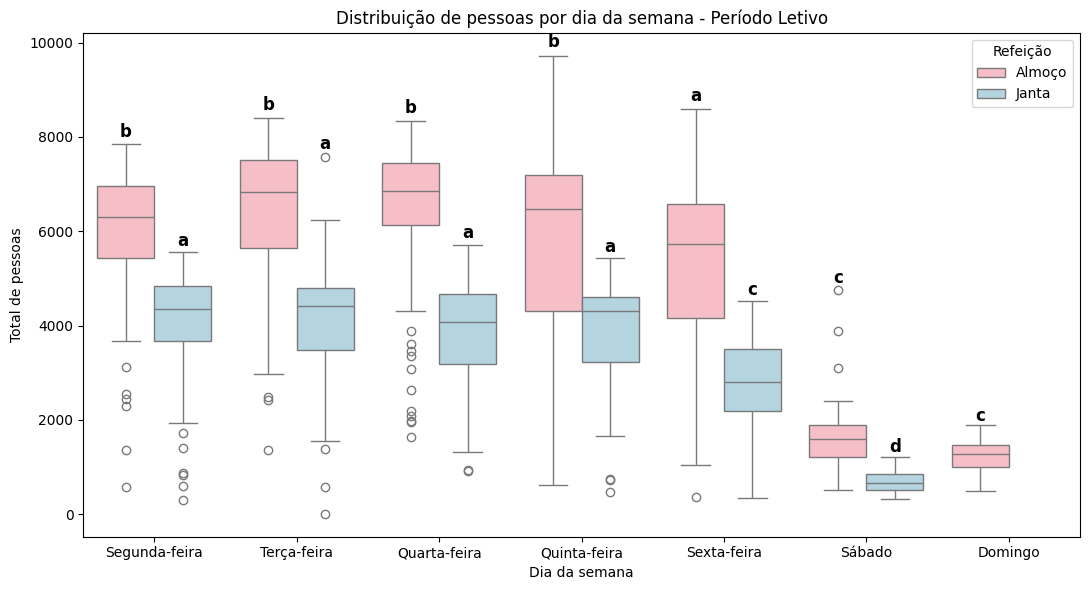

In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns
import networkx as nx  # não esquecer de importar isso!

# Criar coluna com tipo de refeição e combinar os dois DataFrames
almoco = main_almoco_letivo.copy()
almoco["Refeição"] = "Almoço"

janta = main_janta_letivo.copy()
janta["Refeição"] = "Janta"

# Unir e preencher valores ausentes com 0
main_total = pd.concat([almoco, janta])
main_total["Total"] = main_total["Total"].fillna(0)

# Adicionar coluna com o nome do dia da semana
dias_dict = {
    0: "Segunda-feira",
    1: "Terça-feira",
    2: "Quarta-feira",
    3: "Quinta-feira",
    4: "Sexta-feira",
    5: "Sábado",
    6: "Domingo"
}
main_total["DiaSemana"] = main_total.index.weekday.map(dias_dict)

# Reordenar categorias
dias_ordem = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]
main_total["DiaSemana"] = pd.Categorical(main_total["DiaSemana"], categories=dias_ordem, ordered=True)

# Criar coluna combinada para análise estatística
main_total["Grupo"] = main_total["DiaSemana"].astype(str) + " - " + main_total["Refeição"]

# Teste de Kruskal-Wallis
grupos = [main_total.loc[main_total["Grupo"] == g, "Total"] for g in sorted(main_total["Grupo"].unique())]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.10f}")

# Teste de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="Grupo", p_adjust="bonferroni")

# Função já definida anteriormente (copie sua versão robusta aqui)
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index.tolist()
    G = nx.Graph()
    G.add_nodes_from(grupos)

    for i, g1 in enumerate(grupos):
        for j, g2 in enumerate(grupos):
            if j <= i:
                continue
            p_val = df_p.loc[g1, g2]
            if p_val > alpha or np.isnan(p_val):
                G.add_edge(g1, g2)

    letras_disponiveis = list("abcdefghijklmnopqrstuvwxyz")
    letras_grupos = {g: "" for g in grupos}
    letra_idx = 0

    while G.number_of_nodes() > 0:
        clique = nx.find_cliques(G)
        clique = sorted(clique, key=lambda x: -len(x))[0]
        letra = letras_disponiveis[letra_idx]
        for grupo in clique:
            letras_grupos[grupo] += letra
            G.remove_node(grupo)
        letra_idx += 1

    return letras_grupos

letras = gerar_letras(dunn)

# Plot com seaborn
plt.figure(figsize=(11, 6))
sns.boxplot(
    x="DiaSemana", y="Total", hue="Refeição", data=main_total,
    order=dias_ordem, palette={"Almoço": "lightpink", "Janta": "lightblue"}
)
plt.title("Distribuição de pessoas por dia da semana - Período Letivo")
plt.ylabel("Total de pessoas")
plt.xlabel("Dia da semana")

# Adicionar letras de significância
for i, dia in enumerate(dias_ordem):
    for j, refeicao in enumerate(["Almoço", "Janta"]):
        grupo = f"{dia} - {refeicao}"
        if grupo in letras:
            y = main_total.loc[(main_total["DiaSemana"] == dia) & (main_total["Refeição"] == refeicao), "Total"].max()
            # Ajuste da posição: deslocar um pouco à esquerda/direita com base em j
            x_offset = -0.2 if refeicao == "Almoço" else 0.2
            plt.text(i + x_offset, y * 1.01, letras[grupo], ha='center', va='bottom',
                     fontsize=12, fontweight='bold')

plt.tight_layout()
plt.legend(title="Refeição")
plt.show()


## Comparação entre dias da semana



Kruskal–Wallis: H = 260.21, p = 0.0000


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\3856960336.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="DiaSemana", y="Total", data=main_total, order=dias_ordem, palette="pastel")


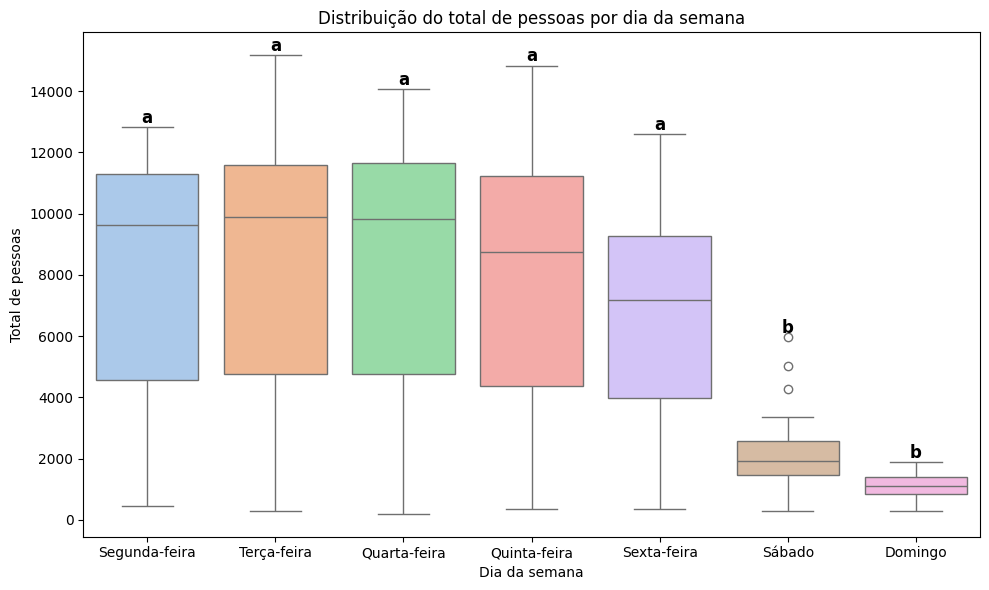

In [189]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# Combinar almoço e janta, mantendo todos os dias
dias_todos = main_almoco.index.union(main_janta.index)

main_total = pd.DataFrame({
    "Total": main_almoco.reindex(dias_todos)["Total"].fillna(0) +
             main_janta.reindex(dias_todos)["Total"].fillna(0)
})

# Adicionar coluna com o nome do dia da semana
# Mapeia os dias da semana (0 = segunda, 6 = domingo)
dias_dict = {
    0: "Segunda-feira",
    1: "Terça-feira",
    2: "Quarta-feira",
    3: "Quinta-feira",
    4: "Sexta-feira",
    5: "Sábado",
    6: "Domingo"
}

main_total["DiaSemana"] = main_total.index.weekday.map(dias_dict)

dias_ordem = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]

# Teste Kruskal–Wallis
grupos = [main_total.loc[main_total["DiaSemana"] == d, "Total"] for d in dias_ordem]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# Teste post hoc de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="DiaSemana", p_adjust="bonferroni")

# Função para gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    """
    Gera letras de significância para um DataFrame de p-valores de comparações múltiplas.

    Parâmetros:
    - df_p: DataFrame simétrico de p-valores (ex: saída de posthoc_dunn)
    - alpha: nível de significância (padrão = 0.05)

    Retorna:
    - dicionário {grupo: letras}
    """
    grupos = df_p.index.tolist()
    G = nx.Graph()

    # Adiciona nós
    G.add_nodes_from(grupos)

    # Adiciona arestas entre grupos que NÃO são significativamente diferentes
    for i, g1 in enumerate(grupos):
        for j, g2 in enumerate(grupos):
            if j <= i:
                continue
            p_val = df_p.loc[g1, g2]
            if p_val > alpha or np.isnan(p_val):  # Não significativamente diferentes
                G.add_edge(g1, g2)

    # Lista de letras
    letras_disponiveis = list("abcdefghijklmnopqrstuvwxyz")
    letras_grupos = {g: "" for g in grupos}
    letra_idx = 0

    # Enquanto ainda houver nós sem letras
    while G.number_of_nodes() > 0:
        # Encontrar um clique máximo (grupos que podem compartilhar uma letra)
        clique = nx.find_cliques(G)
        clique = sorted(clique, key=lambda x: -len(x))[0]  # maior clique
        letra = letras_disponiveis[letra_idx]
        for grupo in clique:
            letras_grupos[grupo] += letra
            G.remove_node(grupo)  # remover para que não receba mais letras
        letra_idx += 1

    return letras_grupos

letras = gerar_letras(dunn)

#  Plot com seaborn
plt.figure(figsize=(10,6))
sns.boxplot(x="DiaSemana", y="Total", data=main_total, order=dias_ordem, palette="pastel")
plt.title("Distribuição do total de pessoas por dia da semana")
plt.ylabel("Total de pessoas")
plt.xlabel("Dia da semana")

# Adicionar letras de significância acima das caixas
positions = range(len(dias_ordem))
for pos, dia in zip(positions, dias_ordem):
    y = main_total.loc[main_total["DiaSemana"] == dia, "Total"].max()
    plt.text(pos, y + 10, letras[dia], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


Kruskal–Wallis: H = 455.81, p = 0.0000000000


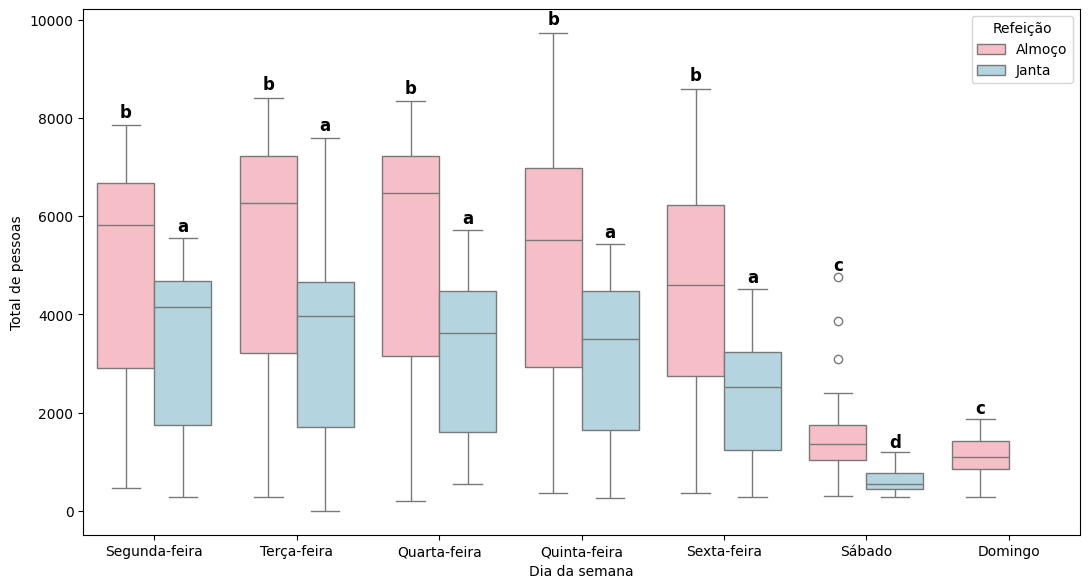

In [190]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns
import networkx as nx  # não esquecer de importar isso!

# Criar coluna com tipo de refeição e combinar os dois DataFrames
almoco = main_almoco.copy()
almoco["Refeição"] = "Almoço"

janta = main_janta.copy()
janta["Refeição"] = "Janta"

# Unir e preencher valores ausentes com 0
main_total = pd.concat([almoco, janta])
main_total["Total"] = main_total["Total"].fillna(0)

# Adicionar coluna com o nome do dia da semana
dias_dict = {
    0: "Segunda-feira",
    1: "Terça-feira",
    2: "Quarta-feira",
    3: "Quinta-feira",
    4: "Sexta-feira",
    5: "Sábado",
    6: "Domingo"
}
main_total["DiaSemana"] = main_total.index.weekday.map(dias_dict)

# Reordenar categorias
dias_ordem = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]
main_total["DiaSemana"] = pd.Categorical(main_total["DiaSemana"], categories=dias_ordem, ordered=True)

# Criar coluna combinada para análise estatística
main_total["Grupo"] = main_total["DiaSemana"].astype(str) + " - " + main_total["Refeição"]

# Teste de Kruskal-Wallis
grupos = [main_total.loc[main_total["Grupo"] == g, "Total"] for g in sorted(main_total["Grupo"].unique())]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.10f}")

# Teste de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="Grupo", p_adjust="bonferroni")

# Função já definida anteriormente (copie sua versão robusta aqui)
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index.tolist()
    G = nx.Graph()
    G.add_nodes_from(grupos)

    for i, g1 in enumerate(grupos):
        for j, g2 in enumerate(grupos):
            if j <= i:
                continue
            p_val = df_p.loc[g1, g2]
            if p_val > alpha or np.isnan(p_val):
                G.add_edge(g1, g2)

    letras_disponiveis = list("abcdefghijklmnopqrstuvwxyz")
    letras_grupos = {g: "" for g in grupos}
    letra_idx = 0

    while G.number_of_nodes() > 0:
        clique = nx.find_cliques(G)
        clique = sorted(clique, key=lambda x: -len(x))[0]
        letra = letras_disponiveis[letra_idx]
        for grupo in clique:
            letras_grupos[grupo] += letra
            G.remove_node(grupo)
        letra_idx += 1

    return letras_grupos

letras = gerar_letras(dunn)

# Plot com seaborn
plt.figure(figsize=(11, 6))
sns.boxplot(
    x="DiaSemana", y="Total", hue="Refeição", data=main_total,
    order=dias_ordem, palette={"Almoço": "lightpink", "Janta": "lightblue"}
)

plt.ylabel("Total de pessoas")
plt.xlabel("Dia da semana")

# Adicionar letras de significância
for i, dia in enumerate(dias_ordem):
    for j, refeicao in enumerate(["Almoço", "Janta"]):
        grupo = f"{dia} - {refeicao}"
        if grupo in letras:
            y = main_total.loc[(main_total["DiaSemana"] == dia) & (main_total["Refeição"] == refeicao), "Total"].max()
            # Ajuste da posição: deslocar um pouco à esquerda/direita com base em j
            x_offset = -0.2 if refeicao == "Almoço" else 0.2
            plt.text(i + x_offset, y * 1.01, letras[grupo], ha='center', va='bottom',
                     fontsize=12, fontweight='bold')

plt.tight_layout()
plt.legend(title="Refeição")
plt.show()


## Comparação entre almoço e janta em período letivo

Mann-Whitney U-test (Período Letivo)
U = 93721.50, p-value = 3.5055e-19


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\2194456056.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


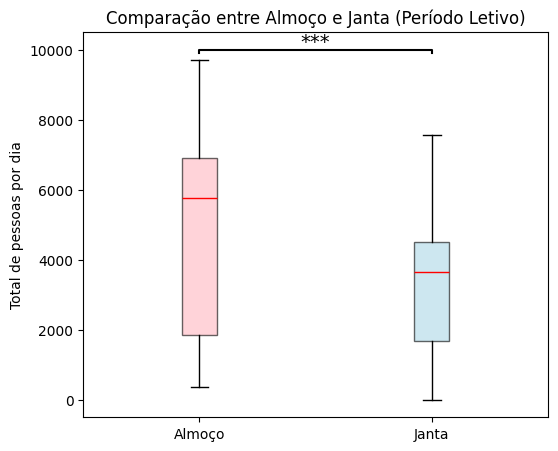

In [191]:
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import numpy as np

# --- Teste Mann-Whitney ---
stat, p_value = mannwhitneyu(main_almoco_letivo["Total"], main_janta_letivo["Total"], alternative='two-sided')

print(f"Mann-Whitney U-test (Período Letivo)")
print(f"U = {stat:.2f}, p-value = {p_value:.4e}")

# --- Boxplot ---
plt.figure(figsize=(6,5))
box = plt.boxplot(
    [main_almoco_letivo["Total"], main_janta_letivo["Total"]],
    labels=["Almoço", "Janta"],
    patch_artist=True,
    medianprops=dict(color='red')
)

# --- Cores personalizadas ---
cores = ['lightpink', 'lightblue']
for patch, cor in zip(box['boxes'], cores):
    patch.set_facecolor(cor)
    patch.set_alpha(0.6)

plt.title("Comparação entre Almoço e Janta (Período Letivo)")
plt.ylabel("Total de pessoas por dia")

# --- Adicionar significância ---
if p_value < 0.001:
    sig = '***'
elif p_value < 0.01:
    sig = '**'
elif p_value < 0.05:
    sig = '*'
else:
    sig = 'ns'

x1, x2 = 1, 2
# --- Ajuste de posição ---
y, h = max(main_almoco_letivo["Total"].max(), main_janta_letivo["Total"].max()) * 1.02, 100  # ↓ de 1.05 para 1.02
plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='black')
plt.text((x1+x2)/2, y+h-50, sig, ha='center', va='bottom', fontsize=14)
plt.show()


Mann-Whitney U-test (Período Letivo)
U = 161268.50, p-value = 4.9409e-16


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\203492999.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


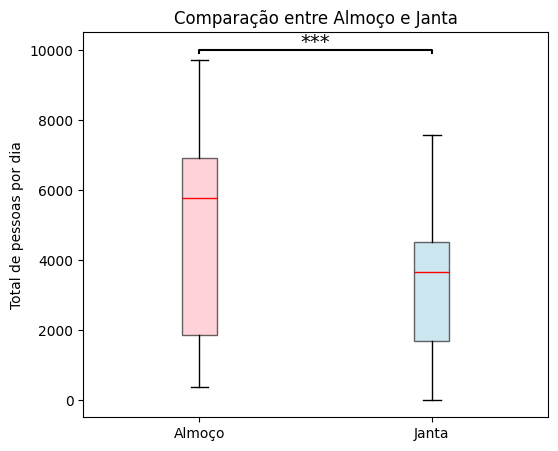

In [192]:
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import numpy as np

# --- Teste Mann-Whitney ---
stat, p_value = mannwhitneyu(main_almoco["Total"], main_janta["Total"], alternative='two-sided')

print(f"Mann-Whitney U-test (Período Letivo)")
print(f"U = {stat:.2f}, p-value = {p_value:.4e}")

# --- Boxplot ---
plt.figure(figsize=(6,5))
box = plt.boxplot(
    [main_almoco_letivo["Total"], main_janta_letivo["Total"]],
    labels=["Almoço", "Janta"],
    patch_artist=True,
    medianprops=dict(color='red')
)

# --- Cores personalizadas ---
cores = ['lightpink', 'lightblue']
for patch, cor in zip(box['boxes'], cores):
    patch.set_facecolor(cor)
    patch.set_alpha(0.6)

plt.title("Comparação entre Almoço e Janta")
plt.ylabel("Total de pessoas por dia")

# --- Adicionar significância ---
if p_value < 0.001:
    sig = '***'
elif p_value < 0.01:
    sig = '**'
elif p_value < 0.05:
    sig = '*'
else:
    sig = 'ns'

x1, x2 = 1, 2
# --- Ajuste de posição ---
y, h = max(main_almoco_letivo["Total"].max(), main_janta_letivo["Total"].max()) * 1.02, 100  # ↓ de 1.05 para 1.02
plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='black')
plt.text((x1+x2)/2, y+h-50, sig, ha='center', va='bottom', fontsize=14)
plt.show()


Mann-Whitney U-test (Período Letivo)
U = 7995.50, p-value = 7.9406e-19


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\2764604289.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


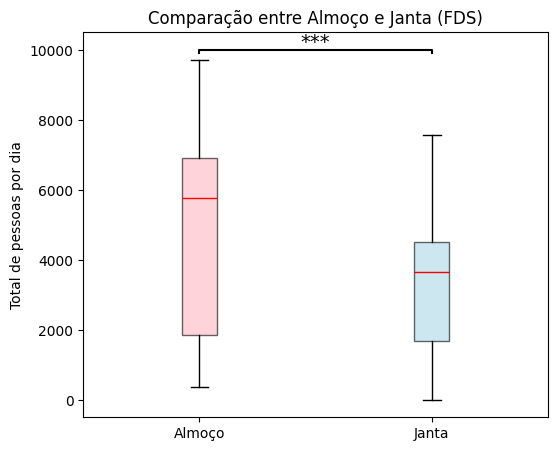

In [193]:
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import numpy as np

# --- Teste Mann-Whitney ---
stat, p_value = mannwhitneyu(main_almoco_fds["Total"], main_janta_fds["Total"], alternative='two-sided')

print(f"Mann-Whitney U-test (Período Letivo)")
print(f"U = {stat:.2f}, p-value = {p_value:.4e}")

# --- Boxplot ---
plt.figure(figsize=(6,5))
box = plt.boxplot(
    [main_almoco_letivo["Total"], main_janta_letivo["Total"]],
    labels=["Almoço", "Janta"],
    patch_artist=True,
    medianprops=dict(color='red')
)

# --- Cores personalizadas ---
cores = ['lightpink', 'lightblue']
for patch, cor in zip(box['boxes'], cores):
    patch.set_facecolor(cor)
    patch.set_alpha(0.6)

plt.title("Comparação entre Almoço e Janta (FDS)")
plt.ylabel("Total de pessoas por dia")

# --- Adicionar significância ---
if p_value < 0.001:
    sig = '***'
elif p_value < 0.01:
    sig = '**'
elif p_value < 0.05:
    sig = '*'
else:
    sig = 'ns'

x1, x2 = 1, 2
# --- Ajuste de posição ---
y, h = max(main_almoco_letivo["Total"].max(), main_janta_letivo["Total"].max()) * 1.02, 100  # ↓ de 1.05 para 1.02
plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='black')
plt.text((x1+x2)/2, y+h-50, sig, ha='center', va='bottom', fontsize=14)
plt.show()


Mann-Whitney U-test (Período Letivo)
U = 117396.00, p-value = 3.2333e-31


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\3809724842.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


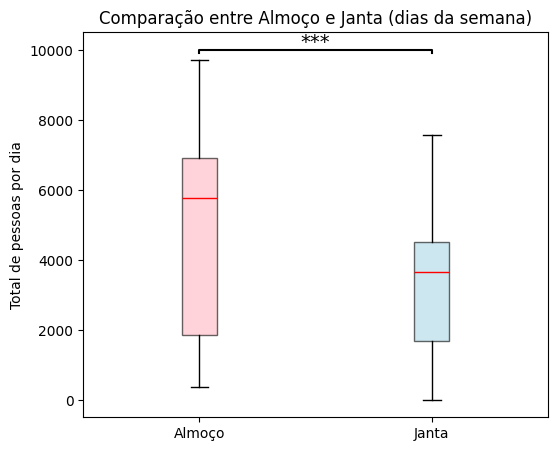

In [194]:
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import numpy as np

# --- Teste Mann-Whitney ---
stat, p_value = mannwhitneyu(main_almoco_semana["Total"], main_janta_semana["Total"], alternative='two-sided')

print(f"Mann-Whitney U-test (Período Letivo)")
print(f"U = {stat:.2f}, p-value = {p_value:.4e}")

# --- Boxplot ---
plt.figure(figsize=(6,5))
box = plt.boxplot(
    [main_almoco_letivo["Total"], main_janta_letivo["Total"]],
    labels=["Almoço", "Janta"],
    patch_artist=True,
    medianprops=dict(color='red')
)

# --- Cores personalizadas ---
cores = ['lightpink', 'lightblue']
for patch, cor in zip(box['boxes'], cores):
    patch.set_facecolor(cor)
    patch.set_alpha(0.6)

plt.title("Comparação entre Almoço e Janta (dias da semana)")
plt.ylabel("Total de pessoas por dia")

# --- Adicionar significância ---
if p_value < 0.001:
    sig = '***'
elif p_value < 0.01:
    sig = '**'
elif p_value < 0.05:
    sig = '*'
else:
    sig = 'ns'

x1, x2 = 1, 2
# --- Ajuste de posição ---
y, h = max(main_almoco_letivo["Total"].max(), main_janta_letivo["Total"].max()) * 1.02, 100  # ↓ de 1.05 para 1.02
plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='black')
plt.text((x1+x2)/2, y+h-50, sig, ha='center', va='bottom', fontsize=14)
plt.show()


## Comparação entre meses do ano (Semana)

Kruskal–Wallis: H = 241.56, p = 0.0000


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\1758471597.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="MesNome", y="Total", data=main_total, order=ordem_meses, palette="pastel")


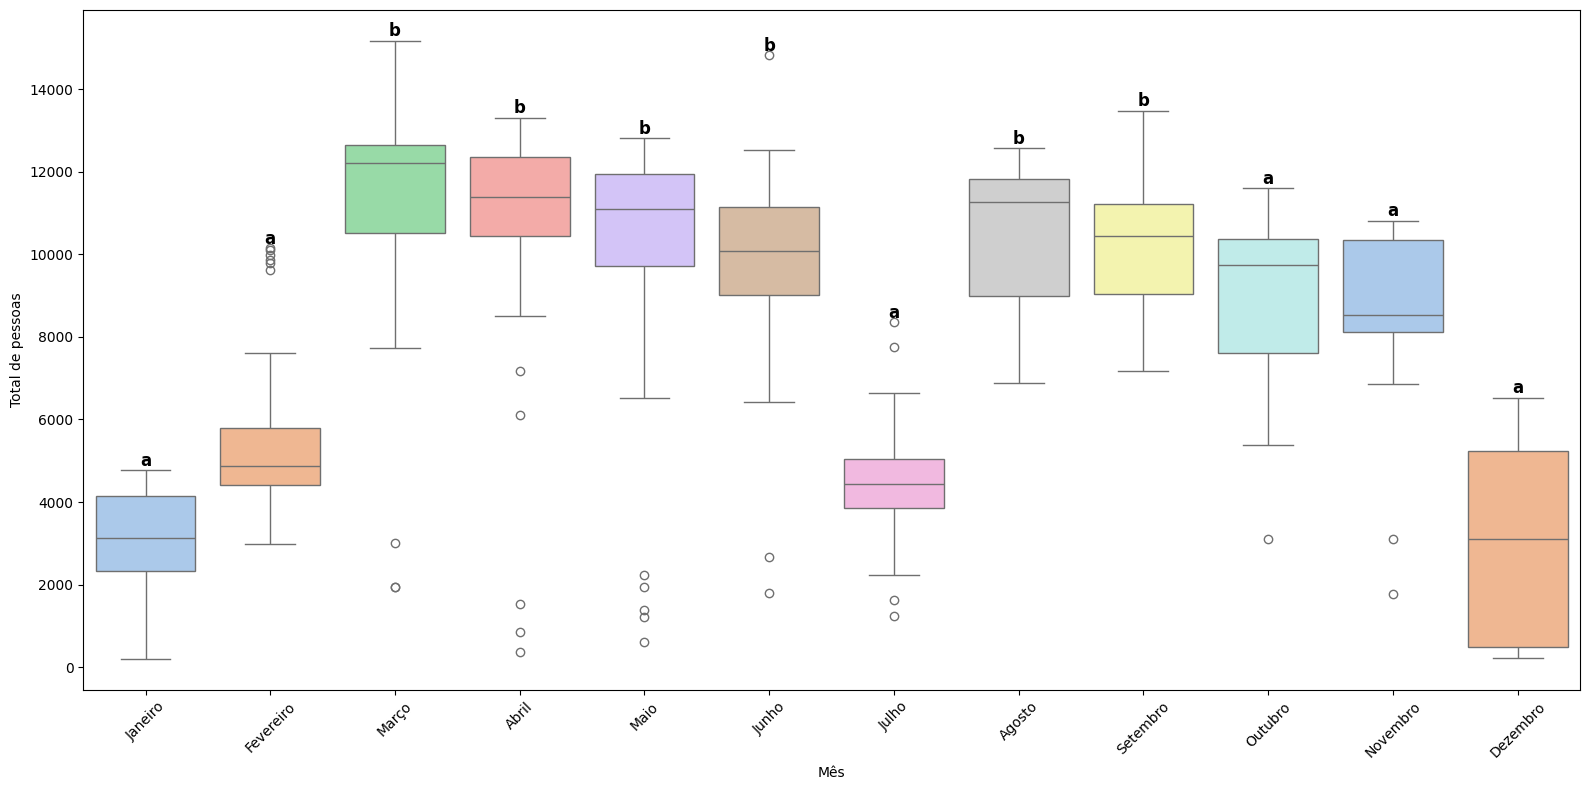

In [195]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# Combinar almoço e janta (igual ao seu código)
dias_todos = main_almoco_semana.index.union(main_janta_semana.index)

main_total = pd.DataFrame({
    "Total": main_almoco_semana.reindex(dias_todos)["Total"].fillna(0) +
             main_janta_semana.reindex(dias_todos)["Total"].fillna(0)
})

# Adicionar coluna com o número e nome do mês
main_total["MesNum"] = main_total.index.month
main_total["MesNome"] = main_total.index.strftime("%B")

# Traduzir nomes dos meses para português
meses_dict = {
    "January": "Janeiro", "February": "Fevereiro", "March": "Março",
    "April": "Abril", "May": "Maio", "June": "Junho",
    "July": "Julho", "August": "Agosto", "September": "Setembro",
    "October": "Outubro", "November": "Novembro", "December": "Dezembro"
}
main_total["MesNome"] = main_total["MesNome"].replace(meses_dict, regex=True)

# Definir ordem correta dos meses (Janeiro → Dezembro)
ordem_meses = list(meses_dict.values())

# 🧪 Teste Kruskal–Wallis (agrupando todos os anos por mês)
grupos = [main_total.loc[main_total["MesNome"] == m, "Total"] for m in ordem_meses]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# 🧮 Teste post hoc de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="MesNome", p_adjust="bonferroni")

# 🩶 Função para gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index
    letras = {g: "" for g in grupos}
    letra_atual = 'a'
    grupos_restantes = set(grupos)

    while grupos_restantes:
        grupo = grupos_restantes.pop()
        letras[grupo] = letra_atual
        comparaveis = [g for g in grupos_restantes if df_p.loc[grupo, g] > alpha]
        for g in comparaveis:
            letras[g] = letra_atual
        grupos_restantes -= set(comparaveis)
        letra_atual = chr(ord(letra_atual) + 1)
    return letras

letras = gerar_letras(dunn)

# 📊 Boxplot por mês (todos os anos juntos)
plt.figure(figsize=(16,8))
sns.boxplot(x="MesNome", y="Total", data=main_total, order=ordem_meses, palette="pastel")
plt.ylabel("Total de pessoas")
plt.xlabel("Mês")

# Adicionar letras de significância
positions = range(len(ordem_meses))
for pos, mes in zip(positions, ordem_meses):
    y = main_total.loc[main_total["MesNome"] == mes, "Total"].max()
    plt.text(pos, y + 10, letras[mes], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Comparação entre meses do ano (Fim de Semana)

Kruskal–Wallis: H = 10.60, p = 0.4775


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\1454753259.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="MesNome", y="Total", data=main_total, order=ordem_meses, palette="pastel")


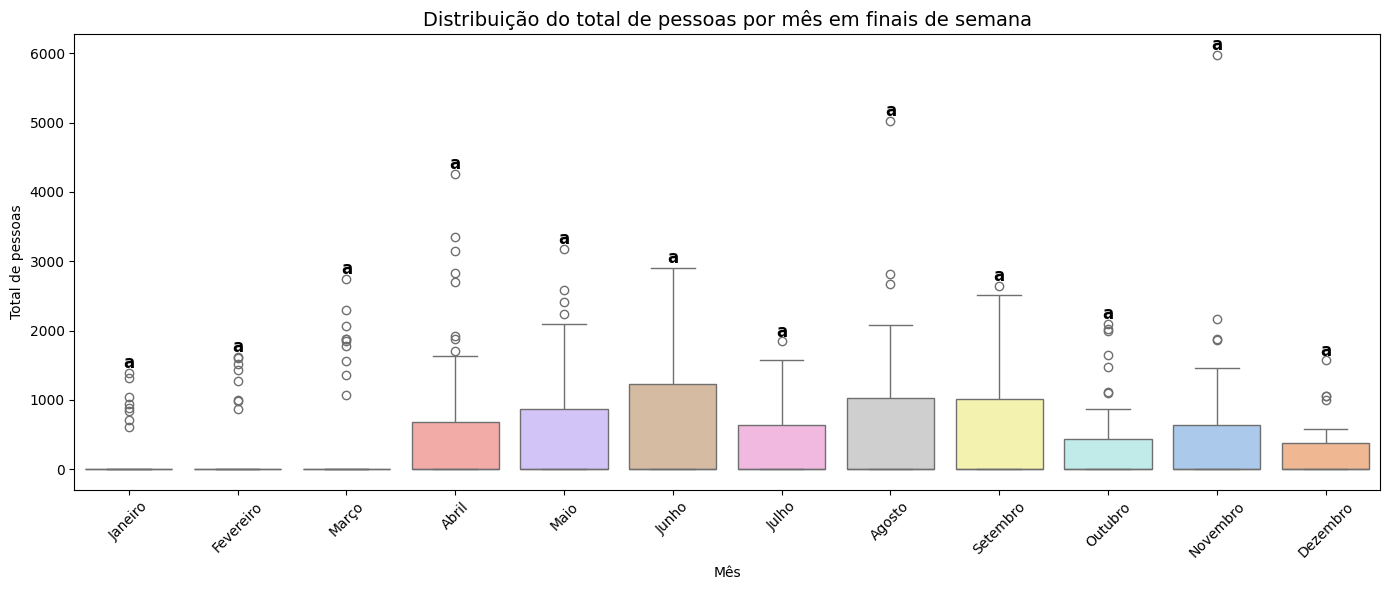

In [196]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# Combinar almoço e janta (igual ao seu código)
dias_todos = main_almoco_fds.index.union(main_janta_semana.index)

main_total = pd.DataFrame({
    "Total": main_almoco_fds.reindex(dias_todos)["Total"].fillna(0) +
             main_janta_fds.reindex(dias_todos)["Total"].fillna(0)
})

# Adicionar coluna com o número e nome do mês
main_total["MesNum"] = main_total.index.month
main_total["MesNome"] = main_total.index.strftime("%B")

# Traduzir nomes dos meses para português
meses_dict = {
    "January": "Janeiro", "February": "Fevereiro", "March": "Março",
    "April": "Abril", "May": "Maio", "June": "Junho",
    "July": "Julho", "August": "Agosto", "September": "Setembro",
    "October": "Outubro", "November": "Novembro", "December": "Dezembro"
}
main_total["MesNome"] = main_total["MesNome"].replace(meses_dict, regex=True)

# Definir ordem correta dos meses (Janeiro → Dezembro)
ordem_meses = list(meses_dict.values())

# 🧪 Teste Kruskal–Wallis (agrupando todos os anos por mês)
grupos = [main_total.loc[main_total["MesNome"] == m, "Total"] for m in ordem_meses]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# 🧮 Teste post hoc de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="MesNome", p_adjust="bonferroni")

# 🩶 Função para gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index
    letras = {g: "" for g in grupos}
    letra_atual = 'a'
    grupos_restantes = set(grupos)

    while grupos_restantes:
        grupo = grupos_restantes.pop()
        letras[grupo] = letra_atual
        comparaveis = [g for g in grupos_restantes if df_p.loc[grupo, g] > alpha]
        for g in comparaveis:
            letras[g] = letra_atual
        grupos_restantes -= set(comparaveis)
        letra_atual = chr(ord(letra_atual) + 1)
    return letras

letras = gerar_letras(dunn)

# 📊 Boxplot por mês (todos os anos juntos)
plt.figure(figsize=(14,6))
sns.boxplot(x="MesNome", y="Total", data=main_total, order=ordem_meses, palette="pastel")
plt.title("Distribuição do total de pessoas por mês em finais de semana", fontsize=14)
plt.ylabel("Total de pessoas")
plt.xlabel("Mês")

# Adicionar letras de significância
positions = range(len(ordem_meses))
for pos, mes in zip(positions, ordem_meses):
    y = main_total.loc[main_total["MesNome"] == mes, "Total"].max()
    plt.text(pos, y + 10, letras[mes], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Comparação entre meses do ano

Kruskal–Wallis: H = 128.29, p = 0.0000


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\987307251.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="MesNome", y="Total", data=main_total, order=ordem_meses, palette="pastel")


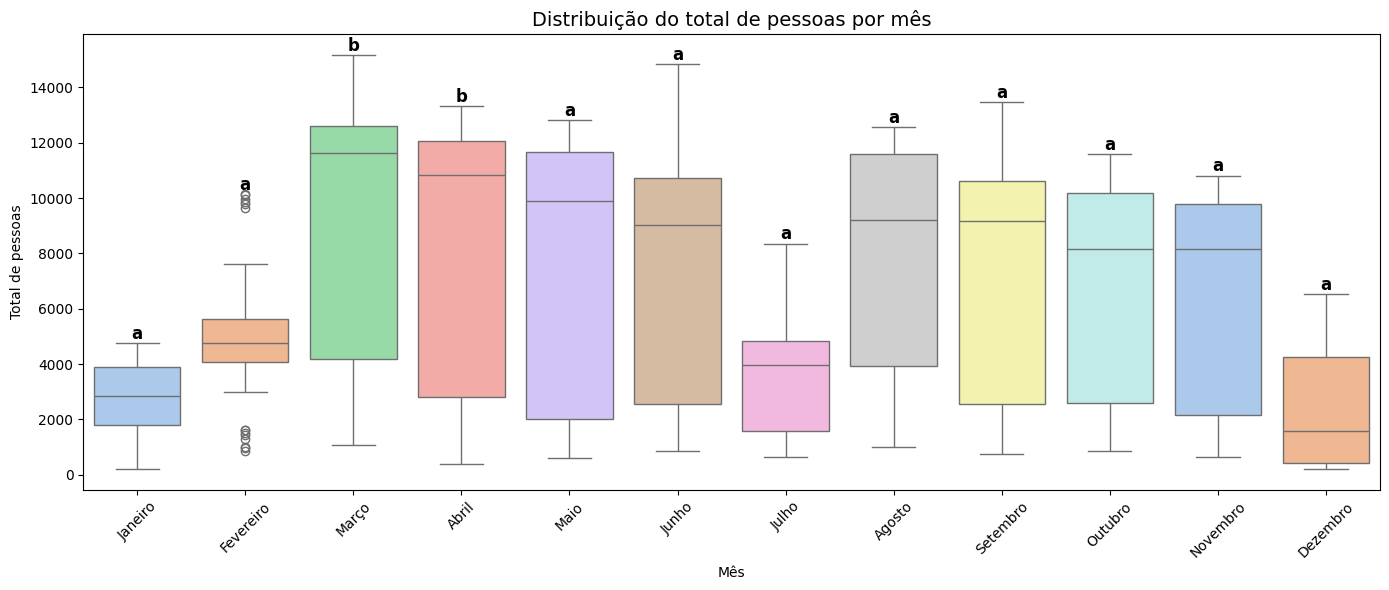

In [197]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# Combinar almoço e janta (igual ao seu código)
dias_todos = main_almoco.index.union(main_janta_semana.index)

main_total = pd.DataFrame({
    "Total": main_almoco.reindex(dias_todos)["Total"].fillna(0) +
             main_janta.reindex(dias_todos)["Total"].fillna(0)
})

# Adicionar coluna com o número e nome do mês
main_total["MesNum"] = main_total.index.month
main_total["MesNome"] = main_total.index.strftime("%B")

# Traduzir nomes dos meses para português
meses_dict = {
    "January": "Janeiro", "February": "Fevereiro", "March": "Março",
    "April": "Abril", "May": "Maio", "June": "Junho",
    "July": "Julho", "August": "Agosto", "September": "Setembro",
    "October": "Outubro", "November": "Novembro", "December": "Dezembro"
}
main_total["MesNome"] = main_total["MesNome"].replace(meses_dict, regex=True)

# Definir ordem correta dos meses (Janeiro → Dezembro)
ordem_meses = list(meses_dict.values())

# 🧪 Teste Kruskal–Wallis (agrupando todos os anos por mês)
grupos = [main_total.loc[main_total["MesNome"] == m, "Total"] for m in ordem_meses]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# 🧮 Teste post hoc de Dunn
dunn = sp.posthoc_dunn(main_total, val_col="Total", group_col="MesNome", p_adjust="bonferroni")

# 🩶 Função para gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index
    letras = {g: "" for g in grupos}
    letra_atual = 'a'
    grupos_restantes = set(grupos)

    while grupos_restantes:
        grupo = grupos_restantes.pop()
        letras[grupo] = letra_atual
        comparaveis = [g for g in grupos_restantes if df_p.loc[grupo, g] > alpha]
        for g in comparaveis:
            letras[g] = letra_atual
        grupos_restantes -= set(comparaveis)
        letra_atual = chr(ord(letra_atual) + 1)
    return letras

letras = gerar_letras(dunn)

# 📊 Boxplot por mês (todos os anos juntos)
plt.figure(figsize=(14,6))
sns.boxplot(x="MesNome", y="Total", data=main_total, order=ordem_meses, palette="pastel")
plt.title("Distribuição do total de pessoas por mês", fontsize=14)
plt.ylabel("Total de pessoas")
plt.xlabel("Mês")

# Adicionar letras de significância
positions = range(len(ordem_meses))
for pos, mes in zip(positions, ordem_meses):
    y = main_total.loc[main_total["MesNome"] == mes, "Total"].max()
    plt.text(pos, y + 10, letras[mes], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Comparação entre cardápios

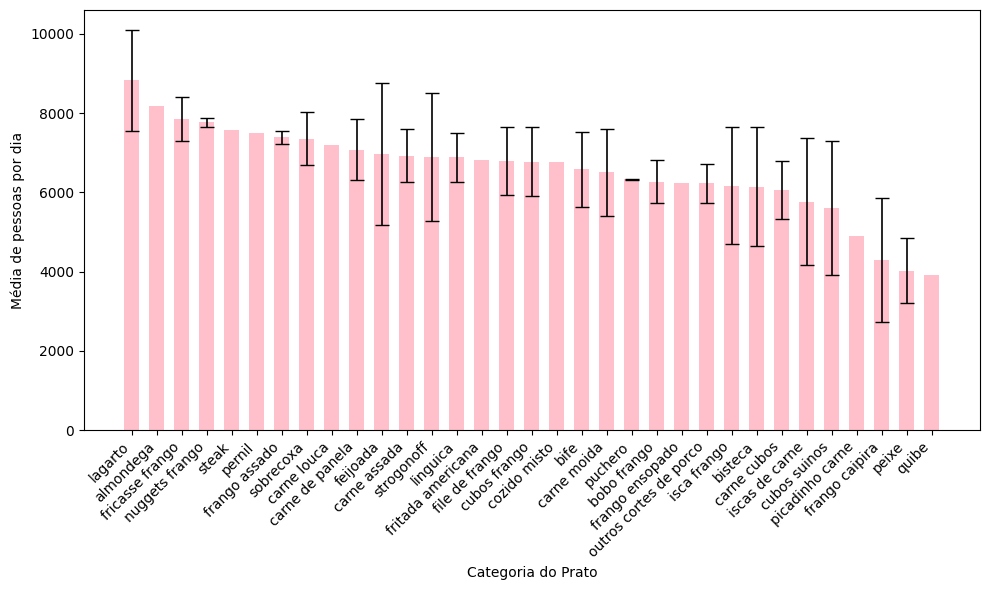

In [199]:
almoco_stats = main_almoco_semana_letivo.groupby("Categoria do Prato")["Total"].agg(["mean", "std"])

# ordenar pela média
almoco_stats = almoco_stats.sort_values(by="mean", ascending=False)

# separa os vetores para o plot
categorias_almoco = almoco_stats.index
media_almoco = almoco_stats["mean"].values
std_almoco   = almoco_stats["std"].values

x = np.arange(len(categorias_almoco))

plt.figure(figsize=(10,6))
plt.bar(x, media_almoco, color="pink", width=0.6,
        yerr=std_almoco, capsize=5, error_kw={'elinewidth':1.2, 'ecolor':'black'})
plt.xticks(x, categorias_almoco, rotation=45, ha="right")
plt.ylabel("Média de pessoas por dia")
plt.xlabel("Categoria do Prato")
plt.tight_layout()
plt.show()

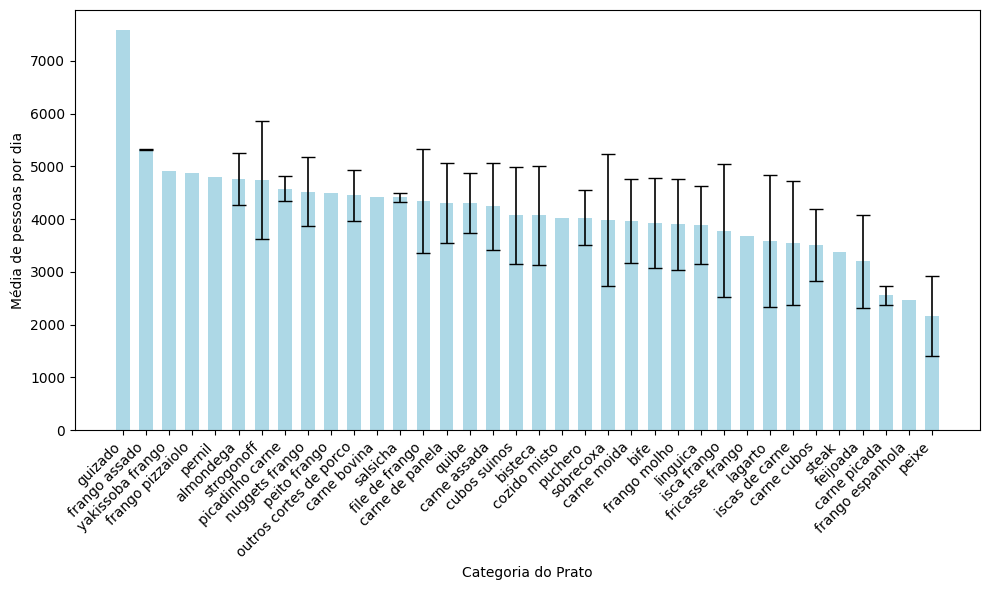

In [211]:
janta_stats = main_janta_semana_letivo.groupby("Categoria do Prato")["Total"].agg(["mean", "std"])

# ordenar pela média
janta_stats = janta_stats.sort_values(by="mean", ascending=False)

# separa os vetores para o plot
categorias_janta = janta_stats.index
media_janta = janta_stats["mean"].values
std_janta   = janta_stats["std"].values

x = np.arange(len(categorias_janta))

plt.figure(figsize=(10,6))
plt.bar(x, media_janta, color="lightblue", width=0.6,
        yerr=std_janta, capsize=5, error_kw={'elinewidth':1.2, 'ecolor':'black'})
plt.xticks(x, categorias_janta, rotation=45, ha="right")
plt.ylabel("Média de pessoas por dia")
plt.xlabel("Categoria do Prato")
plt.tight_layout()
plt.show()

## Analíse post-hoc cardápios

Kruskal–Wallis: H = 120.21, p = 0.0000


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\2845666601.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Categoria do Prato", y="Total", data=df, palette="pastel", order=df["Categoria do Prato"].value_counts().index)


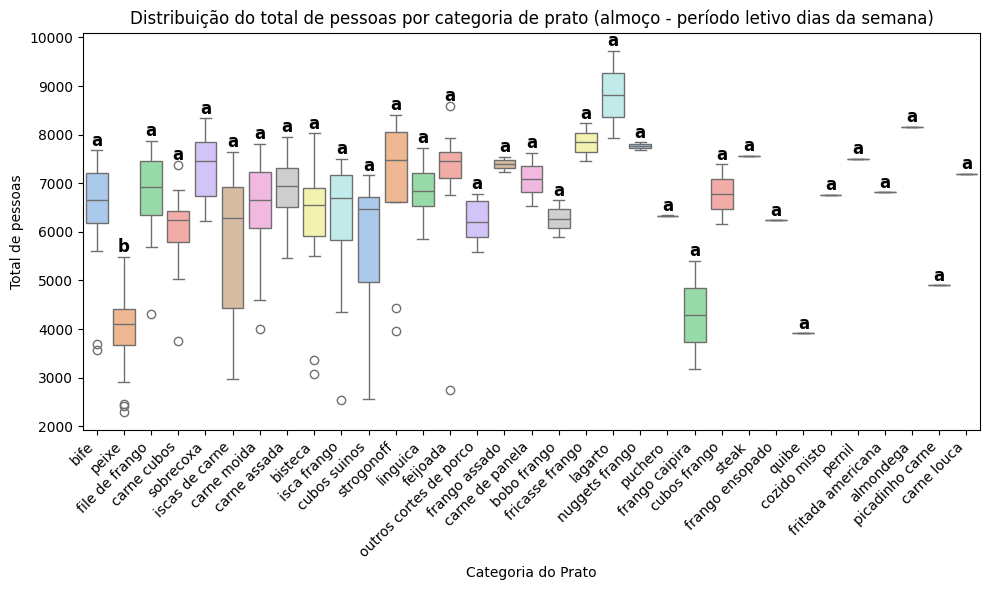

In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# DataFrame: total por categoria
df = main_almoco_letivo.copy()

# Teste Kruskal–Wallis entre categorias
categorias = df["Categoria do Prato"].unique()
grupos = [df.loc[df["Categoria do Prato"] == c, "Total"] for c in categorias]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# Teste post-hoc de Dunn (com correção Bonferroni)
dunn = sp.posthoc_dunn(df, val_col="Total", group_col="Categoria do Prato", p_adjust="bonferroni")

# Gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index
    letras = {g: "" for g in grupos}
    letra_atual = 'a'
    grupos_restantes = set(grupos)

    while grupos_restantes:
        grupo = grupos_restantes.pop()
        letras[grupo] = letra_atual
        comparaveis = [g for g in grupos_restantes if df_p.loc[grupo, g] > alpha]
        for g in comparaveis:
            letras[g] = letra_atual
        grupos_restantes -= set(comparaveis)
        letra_atual = chr(ord(letra_atual) + 1)
    return letras

letras = gerar_letras(dunn)

# Boxplot com seaborn
plt.figure(figsize=(10,6))
sns.boxplot(x="Categoria do Prato", y="Total", data=df, palette="pastel", order=df["Categoria do Prato"].value_counts().index)
plt.title("Distribuição do total de pessoas por categoria de prato (almoço - período letivo dias da semana)")
plt.xlabel("Categoria do Prato")
plt.ylabel("Total de pessoas")

# Adicionar letras de significância
categorias_ordenadas = df["Categoria do Prato"].value_counts().index
for pos, cat in enumerate(categorias_ordenadas):
    y = df.loc[df["Categoria do Prato"] == cat, "Total"].max()
    plt.text(pos, y + 10, letras[cat], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Kruskal–Wallis: H = 120.21, p = 0.0000


C:\Users\João Pedro\AppData\Local\Temp\ipykernel_36168\3501816543.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Categoria do Prato", y="Total", data=df, palette="pastel", order=df["Categoria do Prato"].value_counts().index)


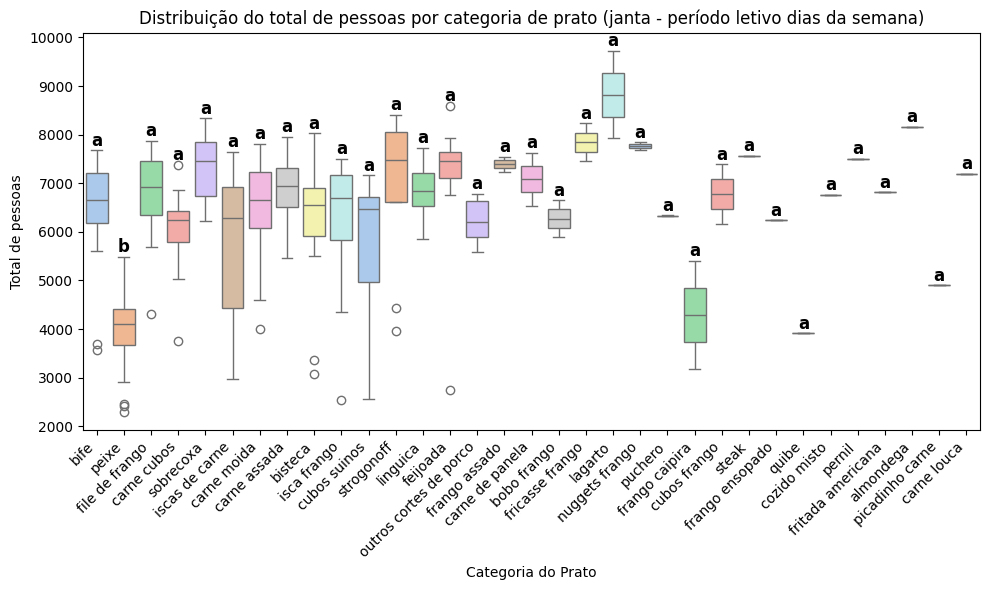

In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import scikit_posthocs as sp
import seaborn as sns

# DataFrame: total por categoria
df = main_almoco_semana_letivo.copy()

# Teste Kruskal–Wallis entre categorias
categorias = df["Categoria do Prato"].unique()
grupos = [df.loc[df["Categoria do Prato"] == c, "Total"] for c in categorias]
H, p = kruskal(*grupos)
print(f"Kruskal–Wallis: H = {H:.2f}, p = {p:.4f}")

# Teste post-hoc de Dunn (com correção Bonferroni)
dunn = sp.posthoc_dunn(df, val_col="Total", group_col="Categoria do Prato", p_adjust="bonferroni")

# Gerar letras de significância
def gerar_letras(df_p, alpha=0.05):
    grupos = df_p.index
    letras = {g: "" for g in grupos}
    letra_atual = 'a'
    grupos_restantes = set(grupos)

    while grupos_restantes:
        grupo = grupos_restantes.pop()
        letras[grupo] = letra_atual
        comparaveis = [g for g in grupos_restantes if df_p.loc[grupo, g] > alpha]
        for g in comparaveis:
            letras[g] = letra_atual
        grupos_restantes -= set(comparaveis)
        letra_atual = chr(ord(letra_atual) + 1)
    return letras

letras = gerar_letras(dunn)

# Boxplot com seaborn
plt.figure(figsize=(10,6))
sns.boxplot(x="Categoria do Prato", y="Total", data=df, palette="pastel", order=df["Categoria do Prato"].value_counts().index)
plt.title("Distribuição do total de pessoas por categoria de prato (janta - período letivo dias da semana)")
plt.xlabel("Categoria do Prato")
plt.ylabel("Total de pessoas")

# Adicionar letras de significância
categorias_ordenadas = df["Categoria do Prato"].value_counts().index
for pos, cat in enumerate(categorias_ordenadas):
    y = df.loc[df["Categoria do Prato"] == cat, "Total"].max()
    plt.text(pos, y + 10, letras[cat], ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# PCA

In [203]:
main_almoco_sem_nan["Dias Semana"] = main_almoco_sem_nan.index.weekday
main_almoco_sem_nan["Mês"] = main_almoco_sem_nan.index.month

In [204]:
valor_categoria = []
for categoria in main_almoco_sem_nan["Categoria do Prato"]:
  valor_categoria.append(int(almoco_categorias_ordenadas.index.get_loc(categoria)))
main_almoco_sem_nan["Valor Categoria"] = valor_categoria

In [205]:
pca_table = main_almoco_sem_nan.copy()
new = pca_table.drop(columns=["Categoria do Prato", "Prato Principal", "RU", "RS", "RA", "Total"])
new
#pca_table.reindex(pca_table["Total"])

,Precipitação,Dias Semana,Mês,Valor Categoria
Data,,,,
2024-01-02,0,1,1,15
2024-01-03,0,2,1,27
2024-01-04,0,3,1,24
2024-01-05,0,4,1,14
2024-01-08,0,0,1,21
...,...,...,...,...
2025-07-25,1016,4,7,8
2025-07-28,0,0,7,23
2025-07-29,0,1,7,26


In [206]:
new_index = main_almoco_sem_nan["Total"]
new = new.set_index(new_index)

In [207]:
# Initialize to reduce the data up to the nubmer of componentes that explains 95% of the variance.
model = pca(n_components=0.95)

# Reduce the data towards 3 PCs
model = pca(n_components=3)

# Fit transform
results = model.fit_transform(new)

[22-10-2026 21:10:20] [pca.pca] [INFO] Extracting column labels from dataframe.
[22-10-2026 21:10:20] [pca.pca] [INFO] Extracting row labels from dataframe.
[22-10-2026 21:10:20] [pca.pca] [INFO] The PCA reduction is performed on the 4 columns of the input dataframe.
[22-10-2026 21:10:20] [pca.pca] [INFO] Fit using PCA.
[22-10-2026 21:10:20] [pca.pca] [INFO] Compute loadings and PCs.
[22-10-2026 21:10:20] [pca.pca] [INFO] Compute explained variance.
[22-10-2026 21:10:20] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[3]
[22-10-2026 21:10:20] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[22-10-2026 21:10:20] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]


[0.99993202 0.99998763 0.99999785]
[9.99932024e-01 5.56053157e-05 1.02209513e-05]


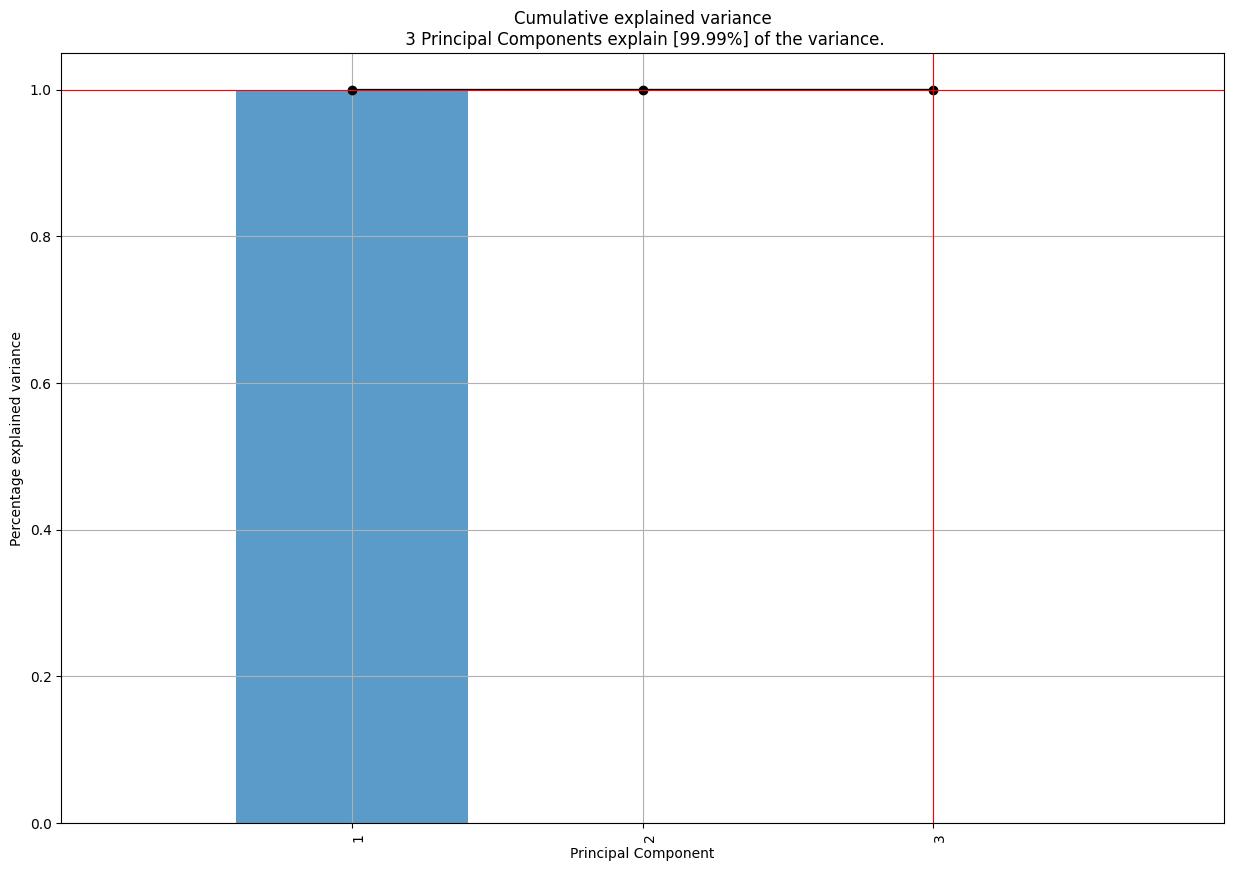

In [208]:
#Cumulative explained variance
print(model.results['explained_var'])


# Explained variance per PC
print(model.results['variance_ratio'])

# Make plot
fig, ax = model.plot()

# Mineração de regras de associação

In [209]:
result_almoco = []
for j in range(len(main_almoco_sem_nan.index)):
  result = []
  for i in range(10):
    if i == np.floor(main_almoco_sem_nan["Total"].iloc[j]/1000):
      result.append(1)
    else:
      result.append(0)
  result_almoco.append(int(np.argmax(result)))

main_almoco_sem_nan["Categoria Volumetria Total"] = result_almoco


In [ ]:
main_almoco_sem_nan

In [ ]:
result_janta = []
for j in range(len(main_janta_sem_nan.index)):
  result = []
  for i in range(10):
    if i == np.floor(main_janta_sem_nan["Total"].iloc[j]/1000):
      result.append(1)
    else:
      result.append(0)
  result_janta.append(int(np.argmax(result)))

main_janta_sem_nan["Categoria Volumetria Total"] = result_janta

In [ ]:
main_janta_sem_nan["Dia da Semana"] = main_janta_sem_nan.index.weekday
main_janta_sem_nan["Mês"] = main_janta_sem_nan.index.month

In [ ]:
valor_categoria = []
for categoria in main_janta_sem_nan["Categoria do Prato"]:
  valor_categoria.append(int(janta_categorias_ordenadas.index.get_loc(categoria)))
main_janta_sem_nan["Valor Categoria"] = valor_categoria

In [ ]:
main_janta_sem_nan

In [ ]:
df_arm_almoco = main_almoco_sem_nan.copy()
df_arm_almoco = df_arm_almoco.drop(columns=["Valor Categoria", "Prato Principal", "RU", "RS", "RA", "Total"])

In [ ]:
def choveu(precipitacao_valor):
  if precipitacao_valor:
    return "choveu"
  return "não choveu"
df_arm_almoco["Precipitação"] = df_arm_almoco["Precipitação"].apply(choveu)

df = df.drop(columns=["Data"], errors="ignore")

In [ ]:
df_arm_almoco

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

In [ ]:
df_arm_almoco["Categoria do Prato"] = df_arm_almoco["Categoria do Prato"].astype(str)
df_arm_almoco["Dias Semana"] = df_arm_almoco["Dias Semana"].astype(str)
df_arm_almoco["Mês"] = df_arm_almoco["Mês"].astype(str)
df_arm_almoco["Categoria Volumetria Total"] = df_arm_almoco["Categoria Volumetria Total"].astype(str)

dados_arm_almoco = df_arm_almoco[[
    "Precipitação",
    "Categoria do Prato",
    "Dias Semana",
    "Mês",
    "Categoria Volumetria Total"
]]
df_apriori = pd.get_dummies(dados_arm_almoco)


In [ ]:
itemsets = apriori(
    df_apriori,
    min_support=0.01,  # pode ajustar
    use_colnames=True
)

In [ ]:
regras = association_rules(
    itemsets,
    metric="confidence",
    min_threshold=0.5   # pode ajustar
)

In [ ]:
volumetria_rules = regras[
    regras['consequents'].astype(str).str.contains("Categoria Volumetria Total")
]
volumetria_lift = volumetria_rules.sort_values(by='lift', ascending=False)

# Mostrar o resultado
print(volumetria_lift.head(100))
volumetria_lift.to_csv("regras.txt", sep="\t", index=False)
